# PR 6: Opening the Transformer
## Attention, Encoder, Decoder and Inference with Pretrained Models

**Objective:** To understand Transformer architecture and explore attention mechanisms, pretrained models, and text generation using Hugging Face.

**Expected Output:** A completed notebook demonstrating tokenization, self-attention, multi-head attention, positional encoding, encoder-decoder architecture, text generation, and model evaluation.

In [1]:
# Install required libraries (run only if not already installed)
%pip install transformers torch datasets matplotlib seaborn numpy pandas

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/604.4 kB ? eta -:--:--
   -------------------------------- ----- 524.3/604.4 kB 882.6 kB/s eta 0:00:01
   ---------------------------------------- 604.4/604.4 kB 841.0 kB/s  0:00:00
   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
    --------------------------------------- 0.5/28.5 MB 1.9 MB/s eta 0:00:16
   - -------------------------------------- 0.8/28.5 MB 2.0 MB/s eta 0:00:15
   - -------------------------------------- 1.3/28.5 MB 1.9 MB/s eta 0:00:15
   -- ------------------------------------- 1.6/28.5 MB 1.9 MB/s eta 0:00:15
   -- ------------------------------------- 1.8/28.5 MB 1.9 MB/s eta 0:00:15
   -- -----------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    GPT2LMHeadModel,
    GPT2Tokenizer,
    T5ForConditionalGeneration,
    T5Tokenizer
)

from datasets import load_dataset
import time
import warnings

warnings.filterwarnings("ignore")

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!
PyTorch version: 2.14.1+cpu
NumPy version: 2.4.6


### Task 1.1 — Sentiment Analysis using a Pretrained Model

**Objective:** To perform sentiment analysis using a pretrained DistilBERT model from Hugging Face.

**Expected Output:** Five sentences classified as POSITIVE or NEGATIVE, along with their confidence scores.

In [3]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

sentences = [
    "I absolutely love learning about artificial intelligence.",
    "This movie was boring and disappointing.",
    "The weather is beautiful today.",
    "I am not happy with the service.",
    "The food was not bad at all."
]

results = sentiment_pipeline(sentences)

for sentence, result in zip(sentences, results):
    print("Sentence:", sentence)
    print("Sentiment:", result["label"])
    print("Confidence:", round(result["score"], 4))
    print("-" * 60)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 247.89it/s]


Sentence: I absolutely love learning about artificial intelligence.
Sentiment: POSITIVE
Confidence: 0.9998
------------------------------------------------------------
Sentence: This movie was boring and disappointing.
Sentiment: NEGATIVE
Confidence: 0.9998
------------------------------------------------------------
Sentence: The weather is beautiful today.
Sentiment: POSITIVE
Confidence: 0.9999
------------------------------------------------------------
Sentence: I am not happy with the service.
Sentiment: NEGATIVE
Confidence: 0.9997
------------------------------------------------------------
Sentence: The food was not bad at all.
Sentiment: POSITIVE
Confidence: 0.9985
------------------------------------------------------------


**Observation:**

The pretrained DistilBERT model successfully classified all five sentences into positive and negative sentiments. It also handled simple negation examples such as "not happy" and "not bad at all". The confidence scores were high, showing that the model was strongly confident in its predictions.

**Conclusion:** A pretrained Transformer model can understand contextual information in text and perform sentiment classification without training a new model.

### Task 1.2 — Evolution of Transformer Architecture

**Objective:** To understand the development of Transformer models and the problems they solved.

**Expected Output:** A timeline of major developments and an explanation of why Transformers replaced traditional sequential models.

| Year | Development |
|---|---|
| 2014–2015 | Sequence-to-sequence models with attention |
| 2017 | Attention Is All You Need introduced the Transformer architecture |
| 2018 | BERT and GPT introduced powerful pretrained language models |
| 2019 | GPT-2, T5 and DistilBERT expanded Transformer applications |
| 2020 onwards | Large Language Models and Vision Transformers became widely used |

**Problems with RNNs and LSTMs:**
1. They process tokens sequentially, making training slower.
2. They can struggle to retain information over long sequences.
3. Parallel processing is difficult.

**How Transformers solve these problems:**

Transformers use self-attention to learn relationships between different tokens. They can process tokens in parallel during training and capture long-distance dependencies more effectively.

### Task 1.3 — Applications and Limitations of Transformers

**Objective:** To identify real-world applications of Transformer architecture and understand its limitations.

**Expected Output:** A list of applications and limitations.

**Applications of Transformers:**

1. Machine Translation – Translating text between languages.
2. Search Engines – Understanding user queries and finding relevant information.
3. Chatbots – Powering conversational AI assistants.
4. Code Generation – Helping developers write and complete code.
5. Image Processing – Vision Transformers are used for image classification.
6. Protein Structure Prediction – Understanding biological sequences and structures.

**Limitations of Transformers:**

1. Computational Cost – Attention can require significant memory and processing power.
2. Context Window – Models have a maximum input length.
3. Large Dataset Requirements – Powerful models often require huge amounts of training data.
4. Hallucinations – Language models can generate incorrect information.
5. Interpretability – Understanding exactly why a model produces a particular output can be difficult.

**Conclusion:**

Transformers have applications across multiple fields, but their computational requirements, context limitations and possibility of generating incorrect information remain important challenges.

### Task 1.4 — Tokenization using DistilBERT

**Objective:** To understand how a pretrained Transformer tokenizer converts text into tokens and numerical IDs.

**Expected Output:** Tokens, input IDs and attention masks for a sample sentence.

A tokenizer converts text into smaller units called tokens. These tokens are then mapped to numerical IDs that can be understood by the model.

DistilBERT uses WordPiece tokenization, which can split uncommon or long words into smaller subword units.

Special tokens:
- `[CLS]` – Represents the beginning of the input sequence.
- `[SEP]` – Represents the separation or ending of a sequence.
- `[PAD]` – Used to make sequences equal in length when padding is applied.

In [4]:
from transformers import AutoTokenizer

# Load DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased-finetuned-sst-2-english"
)

text = "Transformers are surprisingly easy to understand."

# Tokenization
tokens = tokenizer.tokenize(text)
encoded = tokenizer(text)

print("Original Text:")
print(text)

print("\nTokens:")
print(tokens)

print("\nInput IDs:")
print(encoded["input_ids"])

print("\nAttention Mask:")
print(encoded["attention_mask"])

Original Text:
Transformers are surprisingly easy to understand.

Tokens:
['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']

Input IDs:
[101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1]


In [5]:
rare_word = "unbelievably"

print("Word:", rare_word)
print("Subword Tokens:", tokenizer.tokenize(rare_word))

Word: unbelievably
Subword Tokens: ['un', '##bel', '##ie', '##va', '##bly']


**Observation:**

The DistilBERT tokenizer converted the input sentence into seven tokens and generated numerical IDs for each token. It also added `[CLS]` and `[SEP]` special tokens. The attention mask contained only ones because no padding was required. The word "unbelievably" was divided into smaller subword tokens using WordPiece tokenization.

**Conclusion:** Tokenization converts text into numerical representations that Transformer models can process.

### Task 1.5 — Padding and Attention Masks

**Objective:** To understand how padding makes sequences of different lengths equal and how attention masks identify padded tokens.

**Expected Output:** Padded input IDs and corresponding attention masks for two sentences.

In [6]:
sentences = [
    "I love machine learning.",
    "Transformers are powerful models that understand language."
]

encoded_batch = tokenizer(
    sentences,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(encoded_batch["input_ids"])

print("\nAttention Masks:")
print(encoded_batch["attention_mask"])

print("\nInput Shape:", encoded_batch["input_ids"].shape)

Input IDs:
tensor([[  101,  1045,  2293,  3698,  4083,  1012,   102,     0,     0,     0],
        [  101, 19081,  2024,  3928,  4275,  2008,  3305,  2653,  1012,   102]])

Attention Masks:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

Input Shape: torch.Size([2, 10])


**Observation:**

The tokenizer converted both sentences into sequences of equal length (10 tokens). The shorter sentence received three padding tokens with ID 0. Its attention mask contains three zeros, while the longer sentence contains only ones.

**Conclusion:** Padding allows sentences of different lengths to be processed together in a batch, and attention masks distinguish real tokens from padding tokens.

### Task 1.6 — Exploring Pretrained Model Architecture

**Objective:** To inspect the configuration and parameter structure of the pretrained DistilBERT model.

**Expected Output:** Model configuration, parameter count and the names of the first 15 parameters.

In [7]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased-finetuned-sst-2-english"
)

# Model configuration
config = model.config

print("Number of Transformer Layers:", config.n_layers)
print("Number of Attention Heads:", config.n_heads)
print("Hidden Size:", config.dim)
print("Vocabulary Size:", config.vocab_size)
print("Maximum Position Embeddings:", config.max_position_embeddings)

# Total parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal Parameters:", total_parameters)
print("Total Parameters in Millions:", round(total_parameters / 1e6, 2))

# First 15 parameter names
print("\nFirst 15 Model Parameters:")

for name, parameter in list(model.named_parameters())[:15]:
    print(name, parameter.shape)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 397.68it/s]

Number of Transformer Layers: 6
Number of Attention Heads: 12
Hidden Size: 768
Vocabulary Size: 30522
Maximum Position Embeddings: 512

Total Parameters: 66955010
Total Parameters in Millions: 66.96

First 15 Model Parameters:
distilbert.embeddings.word_embeddings.weight torch.Size([30522, 768])
distilbert.embeddings.position_embeddings.weight torch.Size([512, 768])
distilbert.embeddings.LayerNorm.weight torch.Size([768])
distilbert.embeddings.LayerNorm.bias torch.Size([768])
distilbert.transformer.layer.0.attention.q_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.q_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.k_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.k_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.v_lin.weight torch.Size([768, 768])
distilbert.transformer.layer.0.attention.v_lin.bias torch.Size([768])
distilbert.transformer.layer.0.attention.out_lin.weight torch.Size([768, 768])

**Observation:**

The pretrained DistilBERT model contains 6 Transformer layers and 12 attention heads, with a hidden size of 768. It has approximately 66.96 million parameters and supports a maximum sequence length of 512 tokens. The parameter names show its embedding layers, Query-Key-Value projections, attention output layer, normalization layers and feed-forward network.

**Conclusion:** Inspecting the model configuration helps us understand the internal structure of a pretrained Transformer.

### Task 2.1 — Understanding Self-Attention

**Objective:** To understand the Query, Key and Value components of the self-attention mechanism.

**Expected Output:** An explanation of Q, K, V and how scaled dot-product attention works.

Self-attention allows each token to understand its relationship with other tokens in the same sequence.

- Query (Q): Represents what a token is looking for.
- Key (K): Represents the information used to match with a query.
- Value (V): Contains the information that gets combined based on attention weights.

The attention scores are calculated by multiplying Query with the transpose of Key. The scores are divided by the square root of the key dimension and passed through softmax. Finally, the attention weights are multiplied by Value to generate the output.

Transformers can calculate attention across tokens in parallel, unlike traditional RNNs that process sequences one step at a time.

### Task 2.2 — Implementing Self-Attention from Scratch

**Objective:** To implement scaled dot-product self-attention using NumPy without using any pretrained Transformer model.

**Expected Output:** Query, Key, Value matrices, attention scores, attention weights, final output and a 4×4 attention heatmap.

Self-attention calculates the relationships between tokens using Query and Key matrices. Softmax converts the scores into attention weights, which are multiplied by the Value matrix to produce the final output.

In [8]:
# Step 1: Create input data
np.random.seed(42)

X = np.random.rand(4, 8)

# Step 2: Create weight matrices
Wq = np.random.rand(8, 8)
Wk = np.random.rand(8, 8)
Wv = np.random.rand(8, 8)

# Step 3: Calculate Query, Key and Value
Q = X @ Wq
K = X @ Wk
V = X @ Wv

# Step 4: Calculate attention scores
dk = K.shape[1]

scores = (Q @ K.T) / np.sqrt(dk)

# Step 5: Apply stable softmax
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

attention_weights = softmax(scores)

# Step 6: Calculate final attention output
attention_output = attention_weights @ V

# Display results
print("Input Shape:", X.shape)
print("Query Shape:", Q.shape)
print("Key Shape:", K.shape)
print("Value Shape:", V.shape)

print("\nAttention Scores:\n", scores)

print("\nAttention Weights:\n", attention_weights)

print("\nFinal Attention Output:\n", attention_output)

print("\nSum of Attention Weights (each row):")
print(attention_weights.sum(axis=1))

Input Shape: (4, 8)
Query Shape: (4, 8)
Key Shape: (4, 8)
Value Shape: (4, 8)

Attention Scores:
 [[10.97953393  9.03193533  7.75433743  8.08550962]
 [ 8.88618055  7.56463888  6.43157429  6.75191583]
 [ 8.2329139   6.87579249  5.85397777  6.13999791]
 [ 8.69075492  7.37122871  6.21617672  6.5484081 ]]

Attention Weights:
 [[0.80793906 0.11522515 0.03211394 0.04472186]
 [0.67983167 0.18132728 0.05839551 0.08044555]
 [0.67871303 0.17470119 0.06288215 0.08370364]
 [0.6808096  0.18195447 0.05732315 0.07991279]]

Final Attention Output:
 [[1.35626566 2.19219596 2.61079341 1.59942265 1.88567049 1.44798047
  1.73679929 1.94673516]
 [1.35101229 2.15215838 2.52927682 1.58235756 1.87162746 1.47395382
  1.73390762 1.92460159]
 [1.34905951 2.14822183 2.52653519 1.57978649 1.86953633 1.47120131
  1.73445189 1.9210665 ]
 [1.35131633 2.15306647 2.53027107 1.58289659 1.87208295 1.47425501
  1.73388125 1.9252948 ]]

Sum of Attention Weights (each row):
[1. 1. 1. 1.]


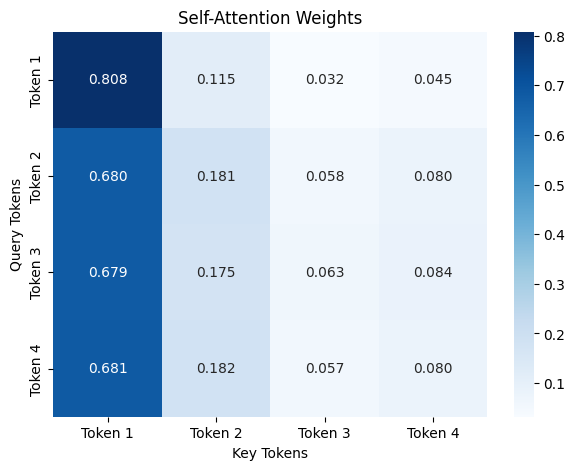

In [9]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    attention_weights,
    annot=True,
    cmap="Blues",
    fmt=".3f",
    xticklabels=["Token 1", "Token 2", "Token 3", "Token 4"],
    yticklabels=["Token 1", "Token 2", "Token 3", "Token 4"]
)

plt.title("Self-Attention Weights")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.show()

**Observation:**

The self-attention mechanism successfully generated Query, Key and Value matrices with shapes (4, 8). The attention weight matrix had a shape of (4, 4), and every row summed to approximately 1 after applying softmax. The heatmap shows that different query tokens assign different attention weights to key tokens.

**Conclusion:** Self-attention calculates relationships between tokens and combines their Value representations according to the attention weights.

### Task 2.3 — Importance of Scaling in Attention

**Objective:** To compare softmax probabilities with and without scaling for different key dimensions.

**Expected Output:** Maximum softmax probabilities for dimensions 4 and 256, with and without scaling.

Scaling attention scores by the square root of the key dimension helps prevent extremely large values from entering the softmax function. Without scaling, softmax can become saturated, resulting in very concentrated attention weights and smaller gradients.

In [10]:
np.random.seed(42)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)


for dk in [4, 256]:

    Q = np.random.randn(10, dk)
    K = np.random.randn(10, dk)

    scores = Q @ K.T

    # Without scaling
    weights_unscaled = softmax(scores)

    # With scaling
    weights_scaled = softmax(scores / np.sqrt(dk))

    print(f"\nKey Dimension: {dk}")

    print(
        "Without Scaling:",
        round(weights_unscaled.max(axis=1).mean(), 4)
    )

    print(
        "With Scaling:",
        round(weights_scaled.max(axis=1).mean(), 4)
    )


Key Dimension: 4
Without Scaling: 0.4853
With Scaling: 0.2862

Key Dimension: 256
Without Scaling: 0.8643
With Scaling: 0.2747


**Observation:**

For a key dimension of 4, the average maximum softmax probability was 0.4853 without scaling and 0.2862 with scaling. For a dimension of 256, it increased to 0.8643 without scaling, while scaling reduced it to 0.2747.

**Conclusion:** Dividing attention scores by the square root of the key dimension prevents softmax saturation and produces less concentrated attention weights.

### Task 2.4 — Implementing Luong Dot-Product Attention

**Objective:** To implement Luong dot-product attention using encoder hidden states and a decoder hidden state.

**Expected Output:** Attention scores, attention weights and a context vector.

Luong attention calculates the similarity between the decoder hidden state and each encoder hidden state. Softmax converts these scores into attention weights, which are used to calculate a weighted context vector from the encoder states.

In [11]:
np.random.seed(42)

# Step 1: Create encoder hidden states
encoder_states = np.random.rand(5, 8)

# Step 2: Create decoder hidden state
decoder_state = np.random.rand(8)

# Step 3: Calculate dot-product attention scores
scores = encoder_states @ decoder_state

# Step 4: Calculate attention weights
attention_weights = softmax(scores)

# Step 5: Calculate context vector
context_vector = attention_weights @ encoder_states

# Display results
print("Encoder States Shape:", encoder_states.shape)
print("Decoder State Shape:", decoder_state.shape)

print("\nAttention Scores:")
print(scores)

print("\nAttention Weights:")
print(attention_weights)

print("\nContext Vector:")
print(context_vector)

print("\nContext Vector Shape:", context_vector.shape)
print("Sum of Attention Weights:", attention_weights.sum())

Encoder States Shape: (5, 8)
Decoder State Shape: (8,)

Attention Scores:
[1.69832472 1.81480545 1.10900188 1.3810714  1.831834  ]

Attention Weights:
[0.21981806 0.24697347 0.12193369 0.1600597  0.25121508]

Context Vector:
[0.35722789 0.81189419 0.49319902 0.69203841 0.48583772 0.13571309
 0.36242915 0.41823604]

Context Vector Shape: (8,)
Sum of Attention Weights: 1.0


**Comparison: Luong Attention vs Self-Attention**

| Luong Attention | Self-Attention |
|---|---|
| Uses encoder and decoder hidden states. | Uses representations from the same sequence. |
| Query comes from the decoder. | Query, Key and Value come from the same input sequence. |
| Helps the decoder focus on relevant input information. | Helps tokens understand relationships with other tokens. |
| Commonly used in encoder-decoder sequence-to-sequence models. | Used in Transformer encoder and decoder blocks. |

**Observation:**

The encoder produced five hidden states, each containing eight features. The decoder hidden state was compared with each encoder state using dot-product attention. The attention weights summed to 1.0, and the fifth encoder state received the highest weight of approximately 0.2512. The final context vector had eight features.

**Conclusion:** Luong attention allows the decoder to focus on relevant encoder information while generating an output sequence.

### Task 2.5 — Demonstrating the Importance of Positional Information

**Objective:** To demonstrate that self-attention without positional encoding does not independently represent token order.

**Expected Output:** A comparison between original and permuted attention outputs, showing that the outputs follow the same permutation.

Self-attention without positional information is permutation-equivariant. This means rearranging the input tokens rearranges the output representations in the same way. Therefore, positional information is required to help Transformers understand token order.

In [12]:
# Original input from Task 2.2
X_original = X.copy()

# Original self-attention output
Q = X_original @ Wq
K = X_original @ Wk
V = X_original @ Wv

scores = (Q @ K.T) / np.sqrt(K.shape[1])
weights = softmax(scores)

original_output = weights @ V

# Rearrange input tokens
permutation = [2, 0, 3, 1]
X_permuted = X_original[permutation]

# Calculate attention on rearranged input
Q_p = X_permuted @ Wq
K_p = X_permuted @ Wk
V_p = X_permuted @ Wv

scores_p = (Q_p @ K_p.T) / np.sqrt(K_p.shape[1])
weights_p = softmax(scores_p)

permuted_output = weights_p @ V_p

# Restore original row order
inverse_permutation = np.argsort(permutation)
restored_output = permuted_output[inverse_permutation]

# Compare
print("Original Output:\n", original_output)

print("\nRestored Permuted Output:\n", restored_output)

print(
    "\nAre both outputs approximately equal?",
    np.allclose(original_output, restored_output)
)

Original Output:
 [[1.35626566 2.19219596 2.61079341 1.59942265 1.88567049 1.44798047
  1.73679929 1.94673516]
 [1.35101229 2.15215838 2.52927682 1.58235756 1.87162746 1.47395382
  1.73390762 1.92460159]
 [1.34905951 2.14822183 2.52653519 1.57978649 1.86953633 1.47120131
  1.73445189 1.9210665 ]
 [1.35131633 2.15306647 2.53027107 1.58289659 1.87208295 1.47425501
  1.73388125 1.9252948 ]]

Restored Permuted Output:
 [[1.35626566 2.19219596 2.61079341 1.59942265 1.88567049 1.44798047
  1.73679929 1.94673516]
 [1.35101229 2.15215838 2.52927682 1.58235756 1.87162746 1.47395382
  1.73390762 1.92460159]
 [1.34905951 2.14822183 2.52653519 1.57978649 1.86953633 1.47120131
  1.73445189 1.9210665 ]
 [1.35131633 2.15306647 2.53027107 1.58289659 1.87208295 1.47425501
  1.73388125 1.9252948 ]]

Are both outputs approximately equal? True


**Observation:**

After rearranging the input tokens, the self-attention output rows were rearranged accordingly. When the original order was restored, both outputs were approximately equal, as confirmed by `np.allclose()` returning True.

**Conclusion:** Self-attention without positional information does not independently represent token positions. Positional embeddings are required to provide information about token order.

### Task 2.6 — Verifying Attention Weights in DistilBERT

**Objective:** To manually calculate attention weights from the Query and Key projections of a real pretrained DistilBERT model and compare them with the model's attention output.

**Expected Output:** Attention tensor shapes and a maximum absolute difference between manually calculated and model-generated attention weights.

Load the model

In [13]:
from transformers import AutoModel

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

attention_model = AutoModel.from_pretrained(
    model_name,
    attn_implementation="eager"
)

attention_model.eval()

print(attention_model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 525.76it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

Calculate attention manually

In [14]:
# Tokenize a sample sentence
text = "Transformers help computers understand human language."

inputs = tokenizer(text, return_tensors="pt")

attention_model.eval()

with torch.no_grad():
    outputs = attention_model(
        **inputs,
        output_attentions=True,
        output_hidden_states=True
    )

# Extract first layer and first attention head
hidden_states = outputs.hidden_states[0]

first_layer = attention_model.transformer.layer[0]
attention = first_layer.attention

# Calculate Query and Key
Q = attention.q_lin(hidden_states)
K = attention.k_lin(hidden_states)

# Split into 12 attention heads
batch_size, seq_length, hidden_size = Q.shape
num_heads = attention_model.config.n_heads
head_dim = hidden_size // num_heads

Q = Q.view(batch_size, seq_length, num_heads, head_dim)
K = K.view(batch_size, seq_length, num_heads, head_dim)

Q = Q.transpose(1, 2)
K = K.transpose(1, 2)

# Calculate scaled dot-product attention
manual_scores = torch.matmul(Q, K.transpose(-1, -2))
manual_scores = manual_scores / np.sqrt(head_dim)

manual_weights = torch.softmax(manual_scores, dim=-1)

# Extract actual attention weights from DistilBERT
actual_weights = outputs.attentions[0]

# Compare first batch, first head
manual_head = manual_weights[0, 0]
actual_head = actual_weights[0, 0]

difference = torch.max(
    torch.abs(manual_head - actual_head)
)

print("Actual Attention Shape:", actual_weights.shape)
print("Manual Attention Shape:", manual_weights.shape)
print("Maximum Absolute Difference:", difference.item())

print(
    "Are the attention weights approximately equal?",
    torch.allclose(manual_head, actual_head, atol=1e-4)
)

Actual Attention Shape: torch.Size([1, 12, 9, 9])
Manual Attention Shape: torch.Size([1, 12, 9, 9])
Maximum Absolute Difference: 0.0
Are the attention weights approximately equal? True


**Observation:**

The actual and manually calculated attention tensors both had a shape of (1, 12, 9, 9). The maximum absolute difference between the first attention head was 0.0, and `torch.allclose()` returned True.

The unused classification-head weights were ignored because only the base DistilBERT model was loaded.

**Conclusion:** The experiment verified that DistilBERT uses scaled dot-product attention, matching our manual implementation.

### Task 3.1 — Understanding Multi-Head Attention

**Objective:** To understand how multiple attention heads work together in a Transformer model.

**Expected Output:** An explanation of multi-head attention and its dimensions.

Multi-head attention performs multiple attention calculations in parallel. Each attention head has its own Query, Key and Value projections and can learn different relationships between tokens.

In DistilBERT, the hidden dimension is 768 and there are 12 attention heads. Therefore, each head has a dimension of 64.

The outputs of all attention heads are concatenated and passed through an output projection to produce the final representation. Multi-head attention helps the model capture different types of relationships within the same input sequence.

### Task 3.2: Visualizing Multi-Head Attention

In this task, we visualize attention weights from six different attention heads of DistilBERT.

The sentence is tokenized, passed through the model, and attention weights are extracted from different layers and heads.

Heatmaps help us observe how each token attends to other tokens in the sentence.

In [15]:
text = "The animal did not cross the street because it was too tired."

inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = attention_model(
        **inputs,
        output_attentions=True
    )

attentions = outputs.attentions

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)
print("Number of layers:", len(attentions))
print("Attention shape:", attentions[0].shape)

Tokens: ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']
Number of layers: 6
Attention shape: torch.Size([1, 12, 15, 15])


Plot six attention heads

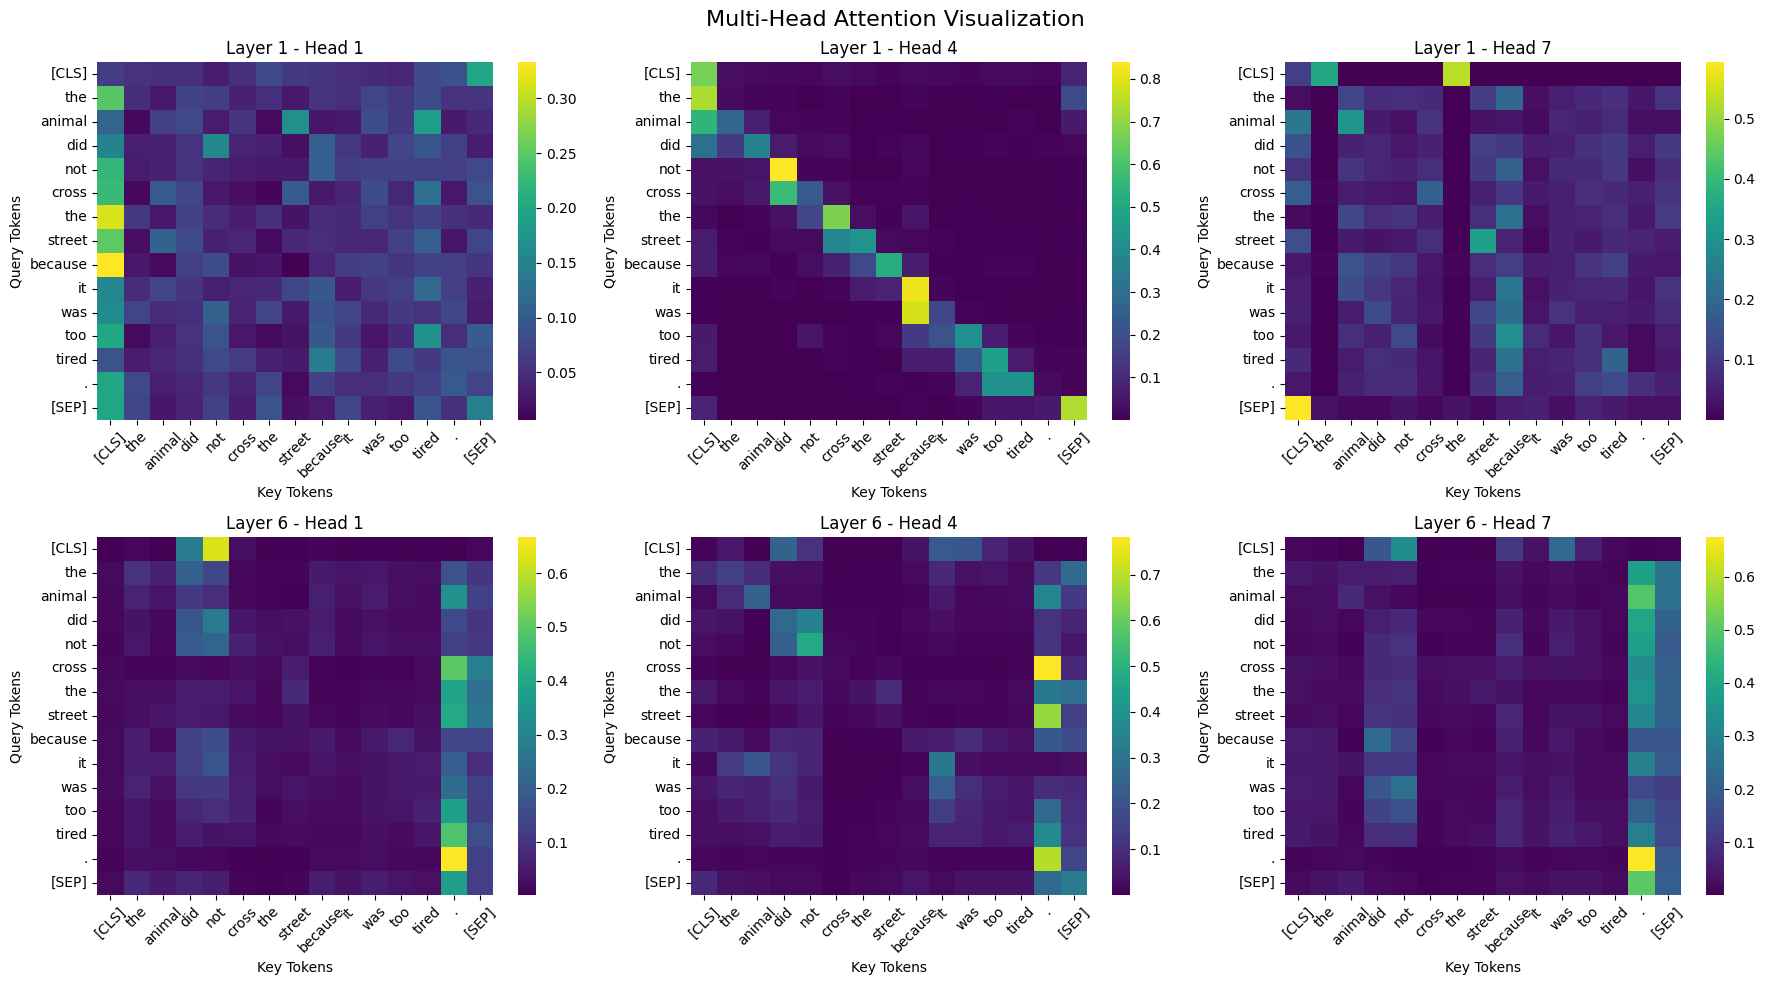

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select 6 heads from the first and last layers
selected_heads = [
    (0, 0), (0, 3), (0, 6),
    (5, 0), (5, 3), (5, 6)
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (layer, head) in zip(axes.flatten(), selected_heads):

    # Extract attention weights
    attention_weights = attentions[layer][0, head].cpu().numpy()

    sns.heatmap(
        attention_weights,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        ax=ax
    )

    ax.set_title(f"Layer {layer + 1} - Head {head + 1}")
    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Multi-Head Attention Visualization", fontsize=16)
plt.tight_layout()
plt.show()

**Observation:**

The six attention heads show different attention patterns. Some heads focus strongly on nearby or individual tokens, while others distribute attention across distant tokens. The first and last layers also show different patterns.

For example, Layer 1 Head 4 shows a strong diagonal pattern, whereas some heads in Layer 6 give higher attention to the final tokens. This demonstrates that different attention heads can learn different relationships between tokens.

### Task 3.3: Attention Entropy Across Layers

Attention entropy measures how attention weights are distributed across tokens.

Low entropy indicates concentrated attention, while high entropy indicates more distributed attention.

In this task, we calculate the average attention entropy for each head in the first and last Transformer layers.

In [18]:
import numpy as np

def calculate_entropy(attention):
    attention = attention.cpu().numpy()

    # Avoid log(0)
    attention = np.clip(attention, 1e-12, 1.0)

    # Calculate entropy for each query token
    entropy = -np.sum(
        attention * np.log(attention),
        axis=-1
    )

    # Average across query tokens, keeping one value per head
    return entropy.mean(axis=1)


# First and last layers
first_layer_entropy = calculate_entropy(attentions[0][0])
last_layer_entropy = calculate_entropy(attentions[-1][0])

print("First layer entropy:", first_layer_entropy)
print("Last layer entropy:", last_layer_entropy)

First layer entropy: [2.4938593  2.0654254  0.5533033  1.2512386  2.3134909  2.1365116
 2.2453706  1.6156766  1.7954173  1.2444289  0.69944113 1.817328  ]
Last layer entropy: [2.0346465 1.8618734 2.26725   1.8916268 1.9279461 1.9787732 1.9929633
 1.7624975 1.94811   2.291271  2.0654883 2.0923665]


Create the comparison graph

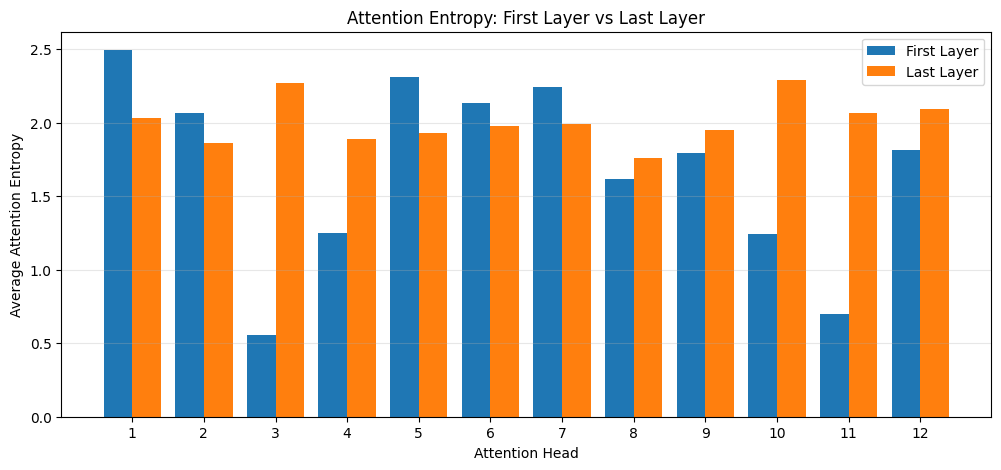

First layer average entropy: 1.6859578
Last layer average entropy: 2.009568


In [19]:
import matplotlib.pyplot as plt

heads = np.arange(1, 13)

plt.figure(figsize=(12, 5))

plt.bar(
    heads - 0.2,
    first_layer_entropy,
    width=0.4,
    label="First Layer"
)

plt.bar(
    heads + 0.2,
    last_layer_entropy,
    width=0.4,
    label="Last Layer"
)

plt.xlabel("Attention Head")
plt.ylabel("Average Attention Entropy")
plt.title("Attention Entropy: First Layer vs Last Layer")
plt.xticks(heads)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

print("First layer average entropy:", first_layer_entropy.mean())
print("Last layer average entropy:", last_layer_entropy.mean())

**Observation:**

The first layer has an average attention entropy of approximately 1.686, while the last layer has approximately 2.010.

This indicates that attention is more distributed on average in the last layer than in the first layer for this particular sentence.

The first layer also shows greater variation between individual heads. Different attention heads distribute their attention differently across tokens.

### Task 3.4: Implementing Sinusoidal Positional Encoding

In this task, we implement sinusoidal positional encoding using NumPy.

We use sine and cosine functions to generate positional information for 50 positions with an embedding dimension of 128.

The positional encoding is added to token embeddings to provide information about token order.

Implement the encoding

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def positional_encoding(max_positions, d_model):

    PE = np.zeros((max_positions, d_model))

    for pos in range(max_positions):
        for i in range(d_model):

            angle = pos / (10000 ** (2 * (i // 2) / d_model))

            if i % 2 == 0:
                PE[pos, i] = np.sin(angle)
            else:
                PE[pos, i] = np.cos(angle)

    return PE


# Generate positional encoding
PE = positional_encoding(50, 128)

print("Positional Encoding Shape:", PE.shape)
print("First position:", PE[0, :10])

Positional Encoding Shape: (50, 128)
First position: [0. 1. 0. 1. 0. 1. 0. 1. 0. 1.]


Visualize positional encoding

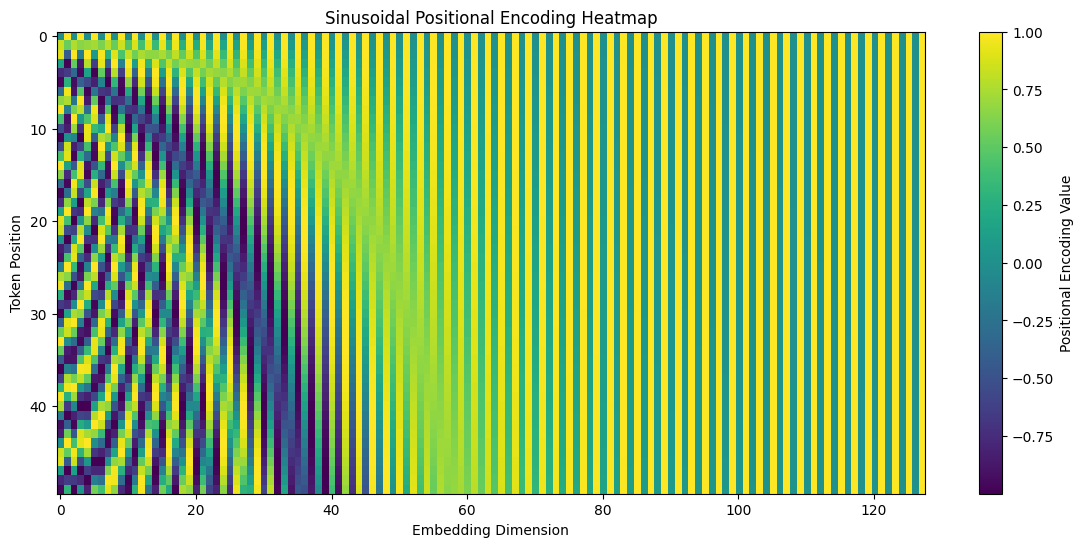

In [21]:
plt.figure(figsize=(14, 6))

plt.imshow(PE, aspect="auto", cmap="viridis")

plt.colorbar(label="Positional Encoding Value")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.title("Sinusoidal Positional Encoding Heatmap")

plt.show()

**Observation:**

The heatmap shows that sinusoidal positional encoding generates different patterns for different token positions and embedding dimensions.

Lower dimensions change more rapidly, while higher dimensions change more slowly. The alternating patterns are produced by sine and cosine functions.

This allows the Transformer to obtain information about token positions and their order.

### Task 3.5: Effect of Positional Encoding

In this task, we compare token representations at two different positions.

We first calculate cosine similarity without positional encoding and then calculate it after adding positional encoding.

This demonstrates how positional encoding introduces position information into token representations.

In [22]:
from numpy.linalg import norm

np.random.seed(42)

# Create one random token embedding
embedding = np.random.rand(128)

# Select two positions
position_3 = PE[3]
position_20 = PE[20]

# Without positional encoding
embedding_3 = embedding.copy()
embedding_20 = embedding.copy()

# With positional encoding
encoded_3 = embedding + position_3
encoded_20 = embedding + position_20


def cosine_similarity(a, b):
    return np.dot(a, b) / (norm(a) * norm(b))


similarity_without = cosine_similarity(
    embedding_3, embedding_20
)

similarity_with = cosine_similarity(
    encoded_3, encoded_20
)

print("Cosine similarity without PE:", similarity_without)
print("Cosine similarity with PE:", similarity_with)

Cosine similarity without PE: 1.0
Cosine similarity with PE: 0.8467851010454543


**Observation:**

Without positional encoding, cosine similarity is 1.0 because the same token embedding is used at both positions.

After adding positional encoding, cosine similarity decreases to approximately 0.847. This shows that positional encoding changes the token representation based on its position.

Therefore, positional encoding helps Transformers distinguish between different token positions.

### Task 3.6: Inspecting Learned Positional Embeddings

DistilBERT uses learned positional embeddings to represent token positions.

In this task, we inspect the positional embedding matrix, calculate cosine similarities between selected positions, and visualize the embeddings using a heatmap.

In [23]:
# Extract learned positional embeddings from DistilBERT
position_embeddings = (
    attention_model.embeddings.position_embeddings.weight
)

position_embeddings = position_embeddings.detach().cpu().numpy()

print("Positional Embedding Shape:", position_embeddings.shape)
print("First 5 position embeddings shape:", position_embeddings[:5].shape)

Positional Embedding Shape: (512, 768)
First 5 position embeddings shape: (5, 768)


Calculate cosine similarity

In [24]:
from sklearn.metrics.pairwise import cosine_similarity

# Select the first 64 positional embeddings
first_64_positions = position_embeddings[:64]

# Calculate pairwise cosine similarity
similarity_matrix = cosine_similarity(first_64_positions)

print("Similarity Matrix Shape:", similarity_matrix.shape)
print("Similarity between position 0 and 1:",
      similarity_matrix[0, 1])

Similarity Matrix Shape: (64, 64)
Similarity between position 0 and 1: 0.030522376


**Observation:**

DistilBERT uses learned positional embeddings with a shape of (512, 768).

The cosine similarity matrix compares the first 64 positional embeddings. The diagonal represents self-similarity, which is 1.0.

The similarity between position 0 and position 1 is approximately 0.0305, indicating that their learned positional representations are quite different.

Unlike sinusoidal positional encoding, learned positional embeddings are optimized during model training.

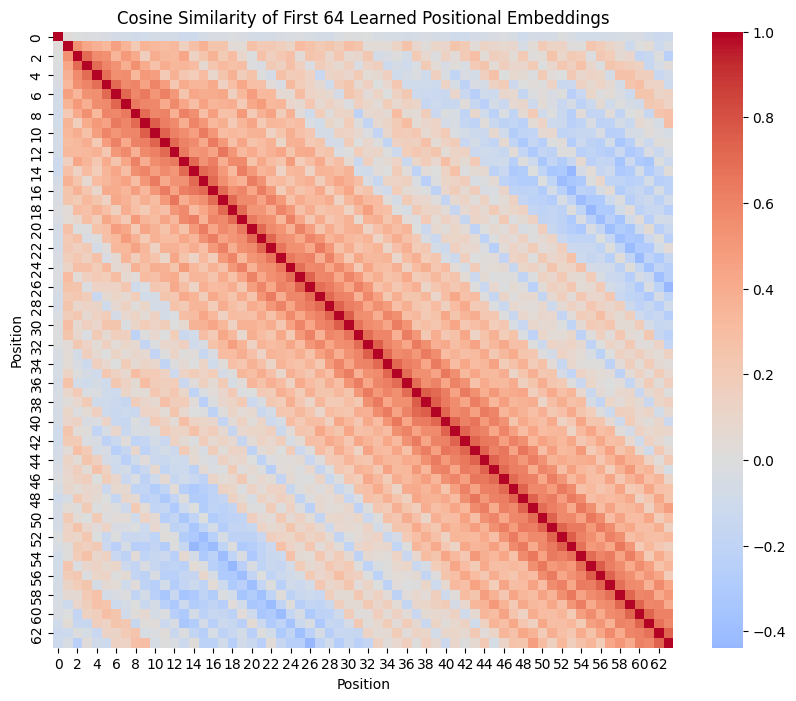

In [25]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    similarity_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Cosine Similarity of First 64 Learned Positional Embeddings")
plt.xlabel("Position")
plt.ylabel("Position")

plt.show()

**Heatmap Observation:**

The diagonal of the heatmap represents self-similarity, which is always 1.0.

Many nearby positions show positive cosine similarity, while some distant positions show negative similarity.

The heatmap demonstrates that DistilBERT learns different positional representations during training. These learned embeddings have their own similarity patterns.

### Task 3.7: Implementing Layer Normalization from Scratch

Layer Normalization normalizes the features of each token independently.

In this task, we implement Layer Normalization using NumPy and compare its output with PyTorch's nn.LayerNorm.

Implement using NumPy

In [27]:
np.random.seed(42)

# Create random input with 4 tokens and 8 features
X = np.random.randn(4, 8)

def layer_norm(X, epsilon=1e-5):
    mean = np.mean(X, axis=1, keepdims=True)
    variance = np.var(X, axis=1, keepdims=True)

    X_normalized = (X - mean) / np.sqrt(variance + epsilon)

    return X_normalized

X_normalized = layer_norm(X)

print("Original Shape:", X.shape)
print("Normalized Shape:", X_normalized.shape)

print("\nMean of each token:")
print(X_normalized.mean(axis=1))

print("\nStandard deviation of each token:")
print(X_normalized.std(axis=1))

Original Shape: (4, 8)
Normalized Shape: (4, 8)

Mean of each token:
[-8.32667268e-17  2.77555756e-17 -5.55111512e-17  2.77555756e-17]

Standard deviation of each token:
[0.99998939 0.99999209 0.99999424 0.99999325]


In [29]:
import torch
import torch.nn as nn

X_torch = torch.tensor(X, dtype=torch.float32)

layer_norm_torch = nn.LayerNorm(8)

with torch.no_grad():
    layer_norm_torch.weight.fill_(1.0)
    layer_norm_torch.bias.fill_(0.0)

torch_output = layer_norm_torch(X_torch).detach().numpy()

print("NumPy and PyTorch outputs match:",
      np.allclose(X_normalized, torch_output, atol=1e-6))

print("Maximum absolute difference:",
      np.max(np.abs(X_normalized - torch_output)))

NumPy and PyTorch outputs match: True
Maximum absolute difference: 1.5385099527698287e-07


**Observation:**

The NumPy implementation was compared with PyTorch's built-in nn.LayerNorm.

Both implementations produced nearly identical outputs. The comparison returned True, with a maximum absolute difference of approximately 1.54 × 10⁻⁷.

This verifies that our Layer Normalization implementation works correctly.

### Task 3.8: Comparing Batch Normalization and Layer Normalization

Layer Normalization normalizes features independently for each token, whereas Batch Normalization normalizes each feature across the batch of tokens.

In this task, we compare both normalization techniques using the same input data and inspect their statistical properties.

In [30]:
# Original input X has shape (4, 8)

# Layer Normalization: normalize across features (axis=1)
layer_mean = X.mean(axis=1, keepdims=True)
layer_var = X.var(axis=1, keepdims=True)

layer_output = (X - layer_mean) / np.sqrt(layer_var + 1e-5)


# Batch Normalization: normalize across tokens (axis=0)
batch_mean = X.mean(axis=0, keepdims=True)
batch_var = X.var(axis=0, keepdims=True)

batch_output = (X - batch_mean) / np.sqrt(batch_var + 1e-5)


print("Layer Normalization:")
print("Mean per token:", layer_output.mean(axis=1))
print("Std per token:", layer_output.std(axis=1))

print("\nBatch Normalization:")
print("Mean per feature:", batch_output.mean(axis=0))
print("Std per feature:", batch_output.std(axis=0))

Layer Normalization:
Mean per token: [-8.32667268e-17  2.77555756e-17 -5.55111512e-17  2.77555756e-17]
Std per token: [0.99998939 0.99999209 0.99999424 0.99999325]

Batch Normalization:
Mean per feature: [-2.77555756e-17 -5.55111512e-17 -5.55111512e-17 -4.16333634e-17
 -5.55111512e-17  5.55111512e-17  2.77555756e-17  0.00000000e+00]
Std per feature: [0.99998339 0.99992081 0.9999895  0.99999572 0.99999178 0.99999037
 0.9999965  0.99999681]


**Observation:**

Layer Normalization calculates mean and variance across the features of each token independently. Therefore, every token has a mean close to 0 and standard deviation close to 1.

Batch Normalization calculates mean and variance across tokens for each feature. Therefore, every feature has a mean close to 0 and standard deviation close to 1.

Layer Normalization is commonly used in Transformers because it works independently for each token and does not depend on batch statistics.

Let's inspect the actual LayerNorm parameters inside DistilBERT.

In [31]:
# Inspect embedding LayerNorm
embedding_layer_norm = attention_model.embeddings.LayerNorm

print("LayerNorm module:")
print(embedding_layer_norm)

print("\nGamma shape:", embedding_layer_norm.weight.shape)
print("Beta shape:", embedding_layer_norm.bias.shape)

LayerNorm module:
LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)

Gamma shape: torch.Size([768])
Beta shape: torch.Size([768])


In [32]:
# Inspect embedding LayerNorm
embedding_layer_norm = attention_model.embeddings.LayerNorm

print("LayerNorm module:")
print(embedding_layer_norm)

print("\nGamma shape:", embedding_layer_norm.weight.shape)
print("Beta shape:", embedding_layer_norm.bias.shape)

LayerNorm module:
LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)

Gamma shape: torch.Size([768])
Beta shape: torch.Size([768])


### Task 4.1: Understanding the Transformer Encoder Architecture

The Transformer encoder consists of multiple encoder blocks.

Each encoder block contains:

1. Multi-Head Self-Attention
2. Residual Connection and Layer Normalization
3. Feed-Forward Neural Network
4. Residual Connection and Layer Normalization

The input first passes through token embeddings and positional embeddings.

In DistilBERT, there are 6 encoder blocks. Each block uses 12 attention heads and a feed-forward network that expands the hidden dimension from 768 to 3072 and projects it back to 768.

The encoder uses bidirectional self-attention, allowing tokens to attend to both previous and following tokens.

### Task 4.2: Inspecting the DistilBERT Architecture

In this task, we inspect the DistilBERT model architecture and identify its embeddings, Transformer blocks, attention layers, feed-forward networks, and LayerNorm modules.

In [33]:
# Print DistilBERT architecture
print(attention_model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [34]:
# Number of Transformer blocks
print("Number of Transformer blocks:",
      len(attention_model.transformer.layer))

# Inspect the first Transformer block
print("\nFirst Transformer Block:")
print(attention_model.transformer.layer[0])

Number of Transformer blocks: 6

First Transformer Block:
TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (activation): GELUActivation()
  )
  (output_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
)


**Observation:**

The DistilBERT model contains an embedding layer followed by six Transformer blocks. Each block consists of a multi-head self-attention mechanism, residual connections, LayerNorm, and a feed-forward network. The feed-forward network expands the hidden dimension from 768 to 3072 and then reduces it back to 768. DistilBERT uses GELU as its activation function.

### Task 4.3: Parameter Count by Component

In this task, we calculate the number of trainable parameters in different components of the DistilBERT model, including embeddings, attention layers, feed-forward networks, and normalization layers.

In [35]:
# Count trainable parameters by component

parameter_groups = {
    "Embeddings": 0,
    "Attention": 0,
    "Feed Forward Network": 0,
    "Layer Normalization": 0
}

for name, param in attention_model.named_parameters():
    if "embeddings" in name:
        parameter_groups["Embeddings"] += param.numel()

    elif "attention" in name:
        parameter_groups["Attention"] += param.numel()

    elif "ffn" in name:
        parameter_groups["Feed Forward Network"] += param.numel()

    elif "LayerNorm" in name or "layer_norm" in name:
        parameter_groups["Layer Normalization"] += param.numel()

for component, count in parameter_groups.items():
    print(f"{component}: {count:,} parameters")

total_parameters = sum(parameter_groups.values())

print(f"\nTotal parameters: {total_parameters:,}")
print(f"Total parameters in millions: {total_parameters / 1_000_000:.2f}M")

Embeddings: 23,835,648 parameters
Attention: 14,174,208 parameters
Feed Forward Network: 28,334,592 parameters
Layer Normalization: 18,432 parameters

Total parameters: 66,362,880
Total parameters in millions: 66.36M


**Observation:**

The DistilBERT base model contains 66,362,880 trainable parameters (approximately 66.36 million). The feed-forward network has the largest parameter count, followed by embeddings and attention layers. Layer normalization contributes a very small number of parameters compared with the other components.

### Task 4.4: Masked Language Modeling with DistilBERT

In this task, we use a pretrained fill-mask pipeline to predict missing words in sentences. The model uses the surrounding context to suggest possible replacements for the masked token.

In [36]:
from transformers import pipeline

# Load pretrained fill-mask pipeline
fill_mask = pipeline(
    "fill-mask",
    model="distilbert-base-uncased"
)

# Test sentences
sentences = [
    "Artificial intelligence is changing the [MASK].",
    "The capital of France is [MASK].",
    "Machine learning helps computers learn from [MASK]."
]

# Predict missing words
for sentence in sentences:
    print("\nSentence:", sentence)

    predictions = fill_mask(sentence, top_k=3)

    for prediction in predictions:
        print(
            prediction["token_str"],
            "->",
            round(prediction["score"], 4)
        )

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 267.25it/s]



Sentence: Artificial intelligence is changing the [MASK].
world -> 0.0832
landscape -> 0.0787
environment -> 0.0751

Sentence: The capital of France is [MASK].
marseille -> 0.1427
nantes -> 0.0902
toulouse -> 0.0881

Sentence: Machine learning helps computers learn from [MASK].
scratch -> 0.0341
computers -> 0.0326
simulations -> 0.0307


**Observation:**

The fill-mask pipeline successfully predicted missing words using surrounding context. For the first sentence, the model predicted "world", while for the second sentence it predicted "Marseille" instead of the correct capital, Paris. This shows that pretrained language models can generate contextually plausible predictions but may not always provide factually correct answers.

### Task 4.5: Visualizing Bidirectional Attention

In this task, we examine the attention weights of DistilBERT to understand how encoder-based Transformer models use information from tokens before and after the current token.

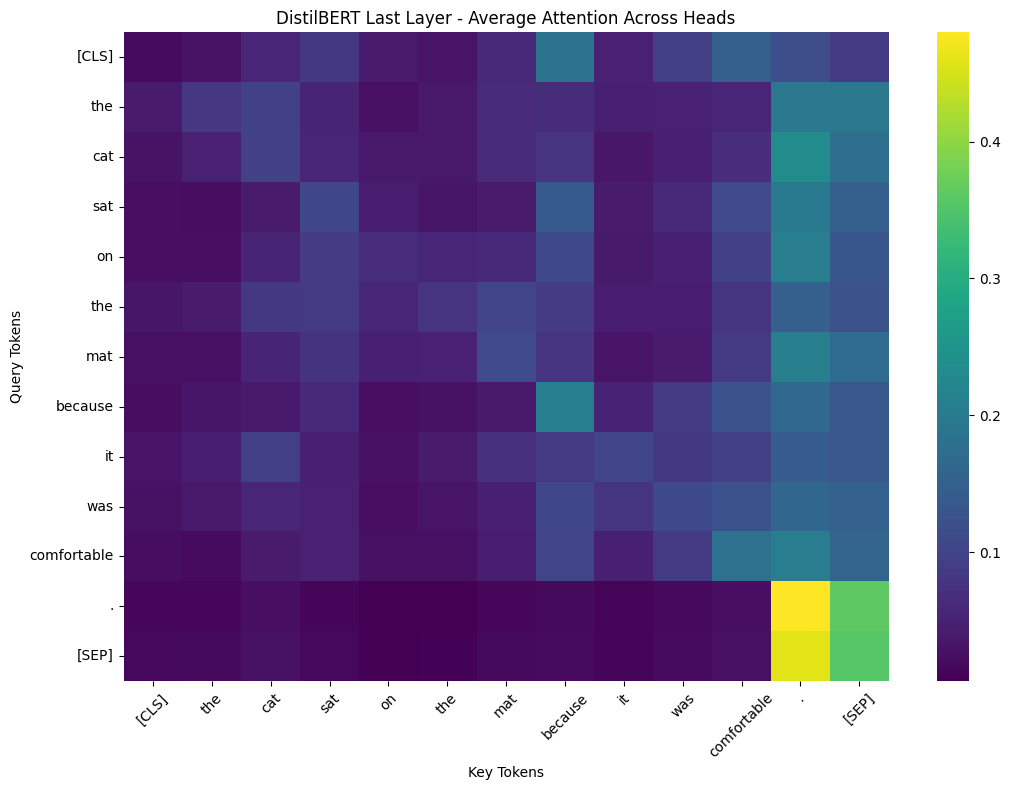

In [37]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sentence = "The cat sat on the mat because it was comfortable."

inputs = tokenizer(sentence, return_tensors="pt")

with torch.no_grad():
    outputs = attention_model(
        **inputs,
        output_attentions=True
    )

# Last Transformer layer attention
last_layer_attention = outputs.attentions[-1][0]

# Average attention across all 12 heads
average_attention = last_layer_attention.mean(dim=0).numpy()

tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    average_attention,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("DistilBERT Last Layer - Average Attention Across Heads")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation:**

The attention heatmap shows that DistilBERT can attend to tokens both before and after the current token. Attention is distributed across different positions rather than being restricted to the diagonal. This demonstrates bidirectional self-attention, which allows the encoder to use context from the entire input sequence.

### Task 4.6: Implementing a Causal Attention Mask

In this task, we implement a causal mask using NumPy. The mask prevents each token from attending to future tokens by assigning negative infinity to positions above the diagonal.

Causal Mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


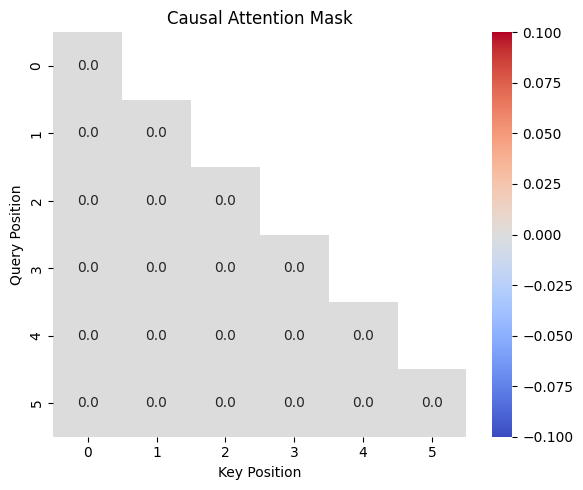

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Number of tokens
seq_len = 6

# Create causal mask
causal_mask = np.triu(
    np.full((seq_len, seq_len), -np.inf),
    k=1
)

print("Causal Mask:")
print(causal_mask)

# Visualize the mask
plt.figure(figsize=(6, 5))
sns.heatmap(
    causal_mask,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    xticklabels=range(seq_len),
    yticklabels=range(seq_len)
)

plt.title("Causal Attention Mask")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.tight_layout()
plt.show()

what happens when the mask is applied before softmax:

In [39]:
# Example attention scores
scores = np.random.randn(seq_len, seq_len)

# Apply causal mask
masked_scores = scores + causal_mask

# Stable softmax
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

causal_attention = softmax(masked_scores)

print("Causal Attention Weights:")
print(np.round(causal_attention, 3))

print("\nRow sums:")
print(causal_attention.sum(axis=-1))

Causal Attention Weights:
[[1.    0.    0.    0.    0.    0.   ]
 [0.179 0.821 0.    0.    0.    0.   ]
 [0.169 0.362 0.469 0.    0.    0.   ]
 [0.313 0.154 0.115 0.418 0.    0.   ]
 [0.074 0.126 0.239 0.455 0.106 0.   ]
 [0.032 0.029 0.216 0.372 0.089 0.262]]

Row sums:
[1. 1. 1. 1. 1. 1.]


**Observation:**

The causal attention mask successfully prevents tokens from attending to future positions. Negative infinity is added to the attention scores above the diagonal, and after applying softmax, those positions receive zero attention weight. Every row of the resulting attention matrix sums to 1. This masking technique is used in decoder-based models such as GPT to support autoregressive text generation.

### Task 4.7: Visualizing GPT-2 Causal Attention

In this task, we inspect the attention weights of GPT-2 and verify that its causal attention mechanism prevents tokens from attending to future positions.

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 186.39it/s]


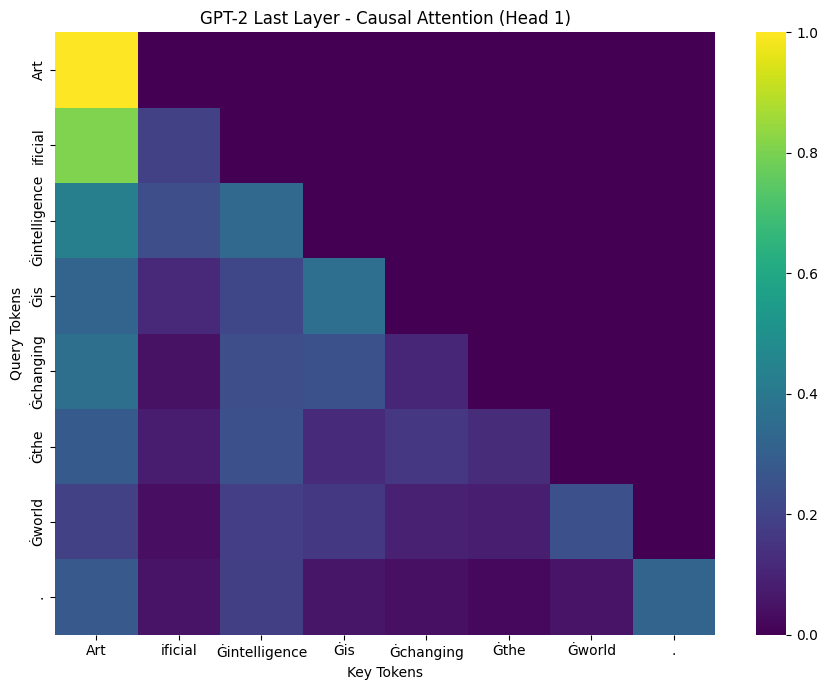

Maximum attention weight on future tokens: 0.0
Future attention blocked: True


In [40]:
from transformers import AutoTokenizer, AutoModel

# Load GPT-2 tokenizer and model
gpt_tokenizer = AutoTokenizer.from_pretrained("gpt2")

gpt_model = AutoModel.from_pretrained(
    "gpt2",
    attn_implementation="eager"
)

gpt_model.eval()

# Input sentence
text = "Artificial intelligence is changing the world."

gpt_inputs = gpt_tokenizer(
    text,
    return_tensors="pt"
)

# Extract attention weights
with torch.no_grad():
    gpt_outputs = gpt_model(
        **gpt_inputs,
        output_attentions=True
    )

# Last layer, first attention head
gpt_attention = gpt_outputs.attentions[-1][0, 0].numpy()

# Get tokens
gpt_tokens = gpt_tokenizer.convert_ids_to_tokens(
    gpt_inputs["input_ids"][0]
)

# Visualize attention
plt.figure(figsize=(9, 7))

sns.heatmap(
    gpt_attention,
    xticklabels=gpt_tokens,
    yticklabels=gpt_tokens,
    cmap="viridis"
)

plt.title("GPT-2 Last Layer - Causal Attention (Head 1)")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
plt.show()

# Verify causal masking
upper_triangle = np.triu(gpt_attention, k=1)

print("Maximum attention weight on future tokens:",
      upper_triangle.max())

print("Future attention blocked:",
      np.allclose(upper_triangle, 0, atol=1e-7))

**Observation:**

The GPT-2 attention heatmap shows a lower-triangular pattern. The first token attends only to itself, while subsequent tokens can attend to previous tokens and their own positions. The maximum attention weight on future tokens was 0.0, and the verification returned True. This confirms that GPT-2 uses causal attention to prevent information leakage from future tokens.

### Task 4.8: Understanding Padding Masks

In this task, we pass sentences of different lengths through DistilBERT and inspect how the attention mask prevents the model from attending to padding tokens.

Input IDs:
tensor([[  101, 19081,  2024,  3928,  1012,   102,     0,     0,     0,     0],
        [  101, 19081,  2024,  3928,  4275,  2008,  3305,  6123,  1012,   102]])

Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


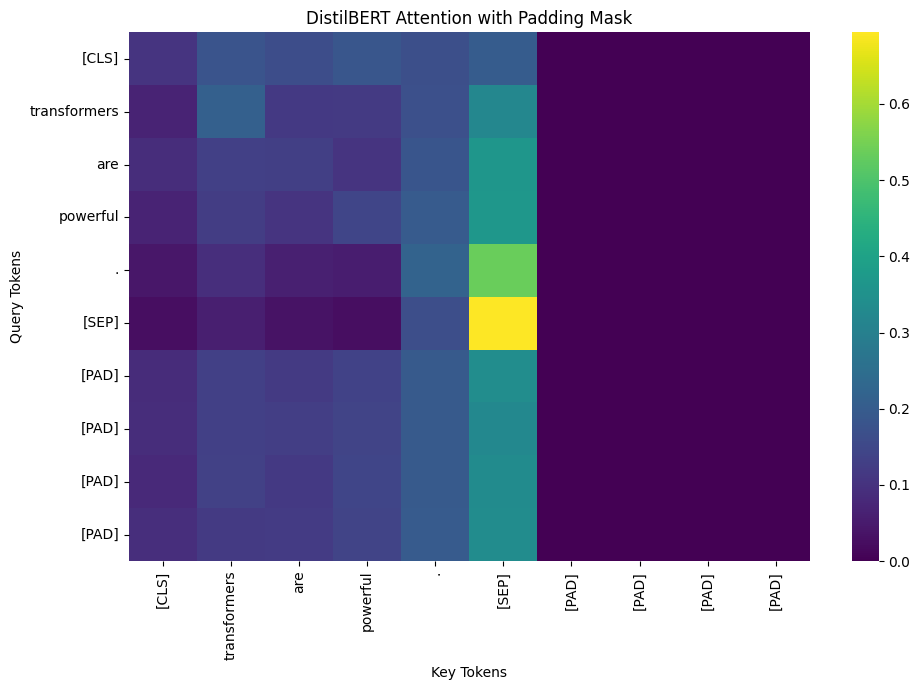

In [41]:
# Two sentences with different lengths
sentences = [
    "Transformers are powerful.",
    "Transformers are powerful models that understand context."
]

# Tokenize with padding
batch_inputs = tokenizer(
    sentences,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch_inputs["input_ids"])

print("\nAttention Mask:")
print(batch_inputs["attention_mask"])

# Run DistilBERT
with torch.no_grad():
    batch_outputs = attention_model(
        **batch_inputs,
        output_attentions=True
    )

# Last layer, average across all heads
batch_attention = batch_outputs.attentions[-1].mean(dim=1)

# Display first sentence attention
first_attention = batch_attention[0].numpy()

tokens = tokenizer.convert_ids_to_tokens(
    batch_inputs["input_ids"][0]
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    first_attention,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("DistilBERT Attention with Padding Mask")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
plt.show()

verification cell:

In [42]:
# Check attention directed toward padding positions
padding_positions = (
    batch_inputs["attention_mask"][0] == 0
).numpy()

print("Padding positions:", padding_positions)

if padding_positions.any():
    padding_attention = first_attention[:, padding_positions]

    print(
        "Maximum attention to padding tokens:",
        padding_attention.max()
    )

Padding positions: [False False False False False False  True  True  True  True]
Maximum attention to padding tokens: 0.0


**Observation:**

The two sentences were padded to the same sequence length of 10 tokens. The first sentence contained four padding tokens, represented by token ID 0 and attention mask value 0. The second sentence required no padding. The maximum attention weight directed towards padding tokens was 0.0, confirming that the attention mask successfully prevents attention to padding positions.

### Task 5.1: Understanding the Transformer Decoder Architecture

The original Transformer decoder consists of the following components:

1. Masked Multi-Head Self-Attention: Allows each token to attend only to previous and current tokens.
2. Add and Norm: Applies a residual connection followed by Layer Normalization.
3. Cross-Attention: Allows the decoder to focus on relevant information from the encoder output.
4. Add and Norm: Applies another residual connection and Layer Normalization.
5. Feed-Forward Network: Processes the token representations.
6. Add and Norm: Applies the final residual connection and Layer Normalization.
7. Linear Layer and Softmax: Produces probabilities over the vocabulary for next-token prediction.

**Three Transformer Model Families:**

- Encoder-only (DistilBERT/BERT): Uses an encoder to understand input text.
- Decoder-only (GPT-2): Uses a decoder with causal self-attention and does not include cross-attention.
- Encoder-decoder (T5): Uses both an encoder and decoder, including cross-attention.

### Task 5.2: Understanding Cross-Attention

In cross-attention, Queries (Q) are generated from the decoder, while Keys (K) and Values (V) come from the encoder output. This allows the decoder to focus on relevant information from the source sequence while generating the target sequence.

Transformer cross-attention is similar to Luong attention. In Luong attention, the decoder hidden state is compared with encoder hidden states to calculate attention scores and a context vector. Transformer cross-attention performs a similar operation using learned Q, K and V projections and scaled dot-product attention.

### Task 5.3: Translation and Summarization using T5

T5 is an encoder-decoder Transformer model that treats every NLP task as a text-to-text problem.

For translation, the encoder processes the input sentence, and the decoder generates the translated sentence.

For summarization, the encoder understands the input paragraph, and the decoder generates a shorter version containing the main information.

Load T5

In [45]:
from transformers import T5Tokenizer, T5ForConditionalGeneration

model_name = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(model_name)
model = T5ForConditionalGeneration.from_pretrained(model_name)

print("T5 model loaded successfully!")

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 502.10it/s]


T5 model loaded successfully!


Perform translation

In [46]:
sentences = [
    "translate English to French: Hello, how are you?",
    "translate English to French: I love learning artificial intelligence.",
    "translate English to French: The weather is beautiful today."
]

for sentence in sentences:
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True)

    outputs = model.generate(
        **inputs,
        max_new_tokens=64
    )

    translation = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("Input:", sentence)
    print("French:", translation)
    print("-" * 50)

Input: translate English to French: Hello, how are you?
French: Bonjour, comment êtes-vous?
--------------------------------------------------
Input: translate English to French: I love learning artificial intelligence.
French: Je m'aime apprendre l'intelligence artificielle.
--------------------------------------------------
Input: translate English to French: The weather is beautiful today.
French: Le temps est beau aujourd'hui.
--------------------------------------------------


**Observation:**

The T5-small model successfully generated French translations for all three English sentences. However, some translations were grammatically unnatural or incorrect. This shows that pretrained models can perform translation without task-specific training, but their outputs are not always perfect.

#### Text Summarization using T5

T5 can also perform summarization by converting a long input paragraph into a shorter version containing its main information. We use the task prefix "summarize:" to tell the model what task to perform.

In [47]:
paragraph = """
Artificial intelligence is transforming many industries around the world.
In healthcare, AI systems help doctors analyze medical images, detect diseases,
and support clinical decisions. In education, AI-powered tools provide
personalized learning experiences and help students understand difficult
concepts. Businesses use AI to automate repetitive tasks, analyze large
amounts of data, and improve customer service. However, AI also creates
challenges related to privacy, bias, job displacement, and reliability.
Therefore, responsible development and ethical use of artificial intelligence
are important for ensuring that its benefits reach society.
"""

inputs = tokenizer(
    "summarize: " + paragraph,
    return_tensors="pt",
    max_length=512,
    truncation=True
)

summary_ids = model.generate(
    **inputs,
    max_length=60,
    min_length=20
)

summary = tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("Original paragraph:")
print(paragraph)

print("\nSummary:")
print(summary)

print("\nOriginal word count:", len(paragraph.split()))
print("Summary word count:", len(summary.split()))

Original paragraph:

Artificial intelligence is transforming many industries around the world.
In healthcare, AI systems help doctors analyze medical images, detect diseases,
and support clinical decisions. In education, AI-powered tools provide
personalized learning experiences and help students understand difficult
concepts. Businesses use AI to automate repetitive tasks, analyze large
amounts of data, and improve customer service. However, AI also creates
challenges related to privacy, bias, job displacement, and reliability.
Therefore, responsible development and ethical use of artificial intelligence
are important for ensuring that its benefits reach society.


Summary:
AI-powered tools help doctors analyze medical images, detect diseases, and support clinical decisions. businesses use AI to automate repetitive tasks, analyze large amounts of data, and improve customer service.

Original word count: 85
Summary word count: 29


**Observation:**

The T5-small model successfully generated a shorter summary of the input paragraph. The original paragraph contained 85 words, while the summary contained 29 words.

The summary retained some important applications of AI, particularly in healthcare and business. However, it missed other details such as education, privacy, bias, and ethical challenges. This shows that automatic summarization can reduce text while potentially losing important context.

### Task 5.4: Visualizing Cross-Attention in T5

Cross-attention allows the decoder to focus on relevant information from the encoder output while generating the target sequence.

In this experiment, we use T5-small for English-to-French translation. We extract the cross-attention weights from the final decoder layer and average them across all attention heads.

A heatmap is used to visualize the relationship between the English input tokens and the generated French output tokens.

Load T5 with attention outputs enabled

In [48]:
from transformers import T5Tokenizer, T5ForConditionalGeneration

model_name = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(model_name)

t5_model = T5ForConditionalGeneration.from_pretrained(
    model_name,
    attn_implementation="eager"
)

print("T5 model loaded successfully!")
print("Number of attention heads:", t5_model.config.num_heads)
print("Number of decoder layers:", t5_model.config.num_decoder_layers)

Loading weights: 100%|██████████| 131/131 [00:01<00:00, 74.37it/s] 


T5 model loaded successfully!
Number of attention heads: 8
Number of decoder layers: 6


Prepare input and expected translation

In [49]:
import torch

input_text = "translate English to French: The house is small."
target_text = "La maison est petite."

inputs = tokenizer(input_text, return_tensors="pt")

labels = tokenizer(
    target_text,
    return_tensors="pt"
).input_ids

print("Input tokens:")
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))

print("\nTarget tokens:")
print(tokenizer.convert_ids_to_tokens(labels[0]))

Input tokens:
['▁translate', '▁English', '▁to', '▁French', ':', '▁The', '▁house', '▁is', '▁small', '.', '</s>']

Target tokens:
['▁La', '▁maison', '▁est', '▁petite', '.', '</s>']


Extract cross-attention

In [50]:
outputs = t5_model(
    input_ids=inputs["input_ids"],
    attention_mask=inputs["attention_mask"],
    labels=labels,
    output_attentions=True,
    return_dict=True
)

cross_attentions = outputs.cross_attentions

print("Number of decoder layers:", len(cross_attentions))
print("Cross-attention shape:", cross_attentions[-1].shape)

Number of decoder layers: 6
Cross-attention shape: torch.Size([1, 8, 6, 11])


Average attention heads and plot heatmap

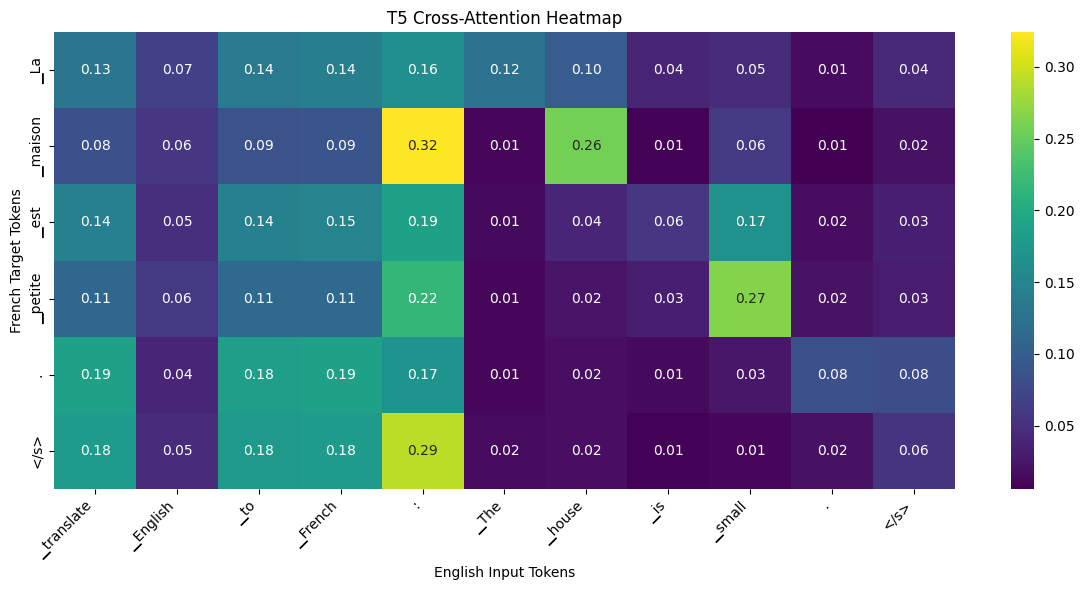

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get cross-attention from the last decoder layer
last_layer_attention = cross_attentions[-1]

# Remove batch dimension
last_layer_attention = last_layer_attention[0]

# Average across all 8 attention heads
avg_attention = last_layer_attention.mean(dim=0)

# Convert to NumPy
avg_attention = avg_attention.detach().numpy()

# Get token labels
input_tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

target_tokens = tokenizer.convert_ids_to_tokens(
    labels[0]
)

# Plot heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    avg_attention,
    xticklabels=input_tokens,
    yticklabels=target_tokens,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title("T5 Cross-Attention Heatmap")
plt.xlabel("English Input Tokens")
plt.ylabel("French Target Tokens")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:**

The cross-attention heatmap visualizes how French output tokens attend to English input tokens.

The token `maison` assigns an attention weight of 0.26 to `house`, while `petite` assigns 0.27 to `small`. This shows that the decoder attends to relevant source words while generating the translation.

However, attention is distributed across multiple tokens, and the strongest attention weight does not always correspond to the direct translation of a word.

### Task 5.5: Manual Greedy Decoding with GPT-2

Greedy decoding is a text-generation strategy in which the model selects the token with the highest probability at every generation step.

In this experiment, we manually implement greedy decoding using GPT-2. We generate 20 new tokens by repeatedly selecting the token with the highest logit value and appending it to the input sequence.

We then compare our manual implementation with the Hugging Face generate() method using greedy decoding.

In [53]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

model_name = "gpt2"

gpt_tokenizer = GPT2Tokenizer.from_pretrained(model_name)

gpt_model = GPT2LMHeadModel.from_pretrained(model_name)

gpt_model.eval()

print("GPT-2 language model loaded successfully!")

Loading weights: 100%|██████████| 148/148 [00:04<00:00, 32.55it/s]


GPT-2 language model loaded successfully!


Manual greedy decoding

In [54]:
import torch

prompt = "Artificial intelligence will"

input_ids = gpt_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

with torch.no_grad():

    for step in range(20):

        outputs = gpt_model(input_ids=input_ids)

        next_token_logits = outputs.logits[:, -1, :]

        next_token = torch.argmax(
            next_token_logits,
            dim=-1,
            keepdim=True
        )

        input_ids = torch.cat(
            [input_ids, next_token],
            dim=-1
        )

manual_output = gpt_tokenizer.decode(
    input_ids[0],
    skip_special_tokens=True
)

print("Manual Greedy Decoding:")
print(manual_output)

Manual Greedy Decoding:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


Compare with Hugging Face generate()

In [55]:
input_ids = gpt_tokenizer(
    "Artificial intelligence will",
    return_tensors="pt"
)["input_ids"]

with torch.no_grad():
    generated_ids = gpt_model.generate(
        input_ids,
        max_new_tokens=20,
        do_sample=False
    )

builtin_output = gpt_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Built-in Greedy Decoding:")
print(builtin_output)

print("\nOutputs match:", manual_output == builtin_output)

Built-in Greedy Decoding:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Outputs match: True


**Observation:**

Manual greedy decoding and Hugging Face's built-in `generate()` method produced identical outputs.

The experiment confirms that greedy decoding selects the token with the highest predicted score at each step and generates text one token at a time.

The generated sentence stopped after 20 new tokens, even though the sentence was incomplete.

### Task 5.6: Comparing Text Generation Strategies

Different decoding strategies affect the quality, diversity, and randomness of generated text.

In this experiment, we compare greedy decoding, beam search, temperature sampling, top-k sampling, and top-p sampling using GPT-2.

We observe how each strategy changes the generated output.

Greedy and Beam Search

In [56]:
prompt = "Artificial intelligence will"

input_ids = gpt_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

# Greedy decoding
greedy_ids = gpt_model.generate(
    input_ids,
    max_new_tokens=40,
    do_sample=False
)

# Beam search
beam_ids = gpt_model.generate(
    input_ids,
    max_new_tokens=40,
    num_beams=5,
    early_stopping=True,
    do_sample=False
)

print("Greedy Decoding:")
print(gpt_tokenizer.decode(greedy_ids[0], skip_special_tokens=True))

print("\nBeam Search:")
print(gpt_tokenizer.decode(beam_ids[0], skip_special_tokens=True))

Greedy Decoding:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.

"We're going to be able to

Beam Search:
Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.

"I think it's going to take a lot of work to get there," he said


**Observation:**

Greedy decoding and beam search generated different text for the same prompt.

Greedy decoding selects the highest-scoring token at each step, while beam search maintains multiple candidate sequences and selects a high-scoring sequence.

Beam search can explore more possible continuations than greedy decoding, but it does not guarantee more accurate or meaningful text.

Temperature sampling

In [57]:
# Temperature sampling
for temperature in [0.7, 1.5]:

    print(f"\nTemperature: {temperature}")

    for seed in [42, 123]:

        torch.manual_seed(seed)

        generated_ids = gpt_model.generate(
            input_ids,
            max_new_tokens=40,
            do_sample=True,
            temperature=temperature,
            pad_token_id=gpt_tokenizer.eos_token_id
        )

        generated_text = gpt_tokenizer.decode(
            generated_ids[0],
            skip_special_tokens=True
        )

        print(f"Seed {seed}:")
        print(generated_text)
        print("-" * 50)


Temperature: 0.7
Seed 42:
Artificial intelligence will be used to create artificial intelligence in the future, but it is not yet a fully mature technology. For example, there is no commercial use of artificial intelligence in the United States. The United States is
--------------------------------------------------
Seed 123:
Artificial intelligence will not only reduce the speed of our daily lives, but also the way we think and behave. This enables us to adapt our lives to change our thinking, so that we will be able to think with
--------------------------------------------------

Temperature: 1.5
Seed 42:
Artificial intelligence will continue to expand a billion ways in just the near future, experts warn, and new tech could help it. The technology is the most widely studied because it looks what you'd describe as a completely separate
--------------------------------------------------
Seed 123:
Artificial intelligence will not only reduce the speed of its process by up to 70%, but 

**Observation:**

Temperature sampling changes the randomness of text generation.

At temperature 0.7, the generated text was relatively conservative and focused on higher-probability tokens.

At temperature 1.5, the outputs were more diverse and unpredictable.

Changing the random seed also produced different outputs at the same temperature. Higher temperature can increase creativity and diversity, but it can also produce less coherent or unreliable text.

Top-k and Top-p sampling

In [58]:
# Top-k sampling
torch.manual_seed(42)

top_k_ids = gpt_model.generate(
    input_ids,
    max_new_tokens=40,
    do_sample=True,
    top_k=50,
    pad_token_id=gpt_tokenizer.eos_token_id
)

# Top-p sampling
torch.manual_seed(42)

top_p_ids = gpt_model.generate(
    input_ids,
    max_new_tokens=40,
    do_sample=True,
    top_p=0.9,
    pad_token_id=gpt_tokenizer.eos_token_id
)

print("Top-k Sampling (k=50):")
print(gpt_tokenizer.decode(top_k_ids[0], skip_special_tokens=True))

print("\nTop-p Sampling (p=0.9):")
print(gpt_tokenizer.decode(top_p_ids[0], skip_special_tokens=True))

Top-k Sampling (k=50):
Artificial intelligence will continue to expand to create new algorithms and more tools to help us learn and understand new kinds of people. The AI's ability to play with different languages, and its tendency to adapt to changes in context

Top-p Sampling (p=0.9):
Artificial intelligence will continue to expand to create new types of AI, but it is still hard to see how we can make an AI that is completely compatible with artificial intelligence. In fact, even if we made an AI


**Observation:**

Top-k and top-p sampling generated different text for the same prompt.

Top-k sampling restricts token selection to the 50 most probable tokens, whereas top-p sampling dynamically selects tokens based on their cumulative probability.

Both methods introduce randomness into text generation and can produce diverse outputs.

### Task 5.7: Comparing Generation Speed With and Without KV Cache

KV Cache stores previously calculated Key and Value tensors during autoregressive text generation.

Without KV Cache, the model repeatedly calculates attention information for previous tokens.

With KV Cache, previously calculated Keys and Values are reused, reducing repeated computation and improving generation efficiency.

In this experiment, we compare GPT-2 generation time with KV Cache enabled and disabled.

Prepare the benchmark

In [59]:
import time
import torch

prompt = "Artificial intelligence is transforming"

input_ids = gpt_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

print("Input shape:", input_ids.shape)
print("Device:", next(gpt_model.parameters()).device)

Input shape: torch.Size([1, 5])
Device: cpu


Run the benchmark

In [60]:
import time
import torch
import numpy as np

def benchmark_generation(use_cache, runs=3):

    # Warm-up
    with torch.no_grad():
        gpt_model.generate(
            input_ids,
            max_new_tokens=100,
            do_sample=False,
            use_cache=use_cache,
            pad_token_id=gpt_tokenizer.eos_token_id
        )

    times = []

    for _ in range(runs):

        start_time = time.perf_counter()

        with torch.no_grad():
            gpt_model.generate(
                input_ids,
                max_new_tokens=100,
                do_sample=False,
                use_cache=use_cache,
                pad_token_id=gpt_tokenizer.eos_token_id
            )

        end_time = time.perf_counter()

        times.append(end_time - start_time)

    return np.mean(times)


# Benchmark without KV Cache
time_without_cache = benchmark_generation(use_cache=False)

# Benchmark with KV Cache
time_with_cache = benchmark_generation(use_cache=True)

print("Average generation time without KV Cache:",
      round(time_without_cache, 3), "seconds")

print("Average generation time with KV Cache:",
      round(time_with_cache, 3), "seconds")

print("Speedup:",
      round(time_without_cache / time_with_cache, 2), "x")

Average generation time without KV Cache: 38.593 seconds
Average generation time with KV Cache: 6.78 seconds
Speedup: 5.69 x


**Observation:**

The average generation time without KV Cache was 38.593 seconds, while generation with KV Cache took 6.780 seconds.

KV Cache achieved a speedup of 5.69x in this experiment.

This demonstrates that storing and reusing previously calculated Key and Value tensors can significantly reduce repeated computations during autoregressive text generation.

The experiment was performed using GPT-2 on CPU, generating 100 new tokens over three measured runs after a warm-up.

## 5.8 Comparison of DistilBERT, GPT-2 and T5

| Feature | DistilBERT | GPT-2 | T5 |
|---|---|---|---|
| Architecture | Encoder-only | Decoder-only | Encoder-decoder |
| Self-Attention | Bidirectional | Causal (masked) | Bidirectional in encoder, causal in decoder |
| Cross-Attention | No | No | Yes |
| Text Generation | Not designed for general text generation | Yes | Yes |
| Positional Encoding | Learned absolute embeddings | Learned absolute embeddings | Relative position bias |
| Main Applications | Sentiment analysis, classification, fill-mask | Text generation and completion | Translation, summarization, question answering |
| Notebook Experiment | Sentiment analysis and masked prediction | Greedy decoding and KV Cache | Translation, summarization and cross-attention |

**Observation:**

DistilBERT, GPT-2 and T5 have different Transformer architectures designed for different tasks.

- DistilBERT uses a bidirectional encoder and is suitable for understanding tasks such as sentiment analysis and classification.
- GPT-2 uses a decoder with causal attention to generate text autoregressively.
- T5 uses both an encoder and decoder, making it suitable for sequence-to-sequence tasks such as translation and summarization.

This comparison helped me understand how the Transformer architecture can be adapted for different NLP applications.

# Task 6: Real-World Transformer Applications and Evaluation

## 6.1 Evaluate the Pretrained Sentiment Model

**Objective:** Evaluate a pretrained DistilBERT sentiment-analysis model on 200 IMDB movie reviews.

**Expected Output:** Predicted sentiment labels, accuracy, precision, recall, F1-score and a confusion matrix.

In [63]:
from datasets import load_dataset

imdb_data = load_dataset("stanfordnlp/imdb", split="test")
imdb_data = imdb_data.shuffle(seed=42).select(range(200))

print("Number of reviews:", len(imdb_data))
print("\nFirst review:")
print(imdb_data[0]["text"][:500])

print("\nFirst review label:", imdb_data[0]["label"])

Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 73428.64 examples/s] 


Number of reviews: 200

First review:
<br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I started crying and couldn't stop until long after the movie ended. Thank you Jane, Laura and Jocelyn, for bringing us such a wonderfully subtle and compassionate movie! Thank you cast, for being involved

First review label: 1


Run sentiment predictions

### 6.1 Evaluate Pretrained Sentiment Model on IMDB Reviews

In this task, I evaluate a pretrained DistilBERT sentiment analysis model on 200 IMDB movie reviews. The model predicts whether each review is positive or negative. I compare its predictions with the actual labels using accuracy, precision, recall, F1-score and a confusion matrix.

In [64]:
from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

reviews = [item["text"] for item in imdb_data]
actual_labels = [item["label"] for item in imdb_data]

predictions = sentiment_model(
    reviews,
    truncation=True,
    max_length=512,
    batch_size=16
)

predicted_labels = [
    1 if result["label"] == "POSITIVE" else 0
    for result in predictions
]

print("Total predictions:", len(predicted_labels))
print("First 5 predictions:", predicted_labels[:5])
print("First 5 actual labels:", actual_labels[:5])

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 588.92it/s]


Total predictions: 200
First 5 predictions: [1, 1, 0, 0, 0]
First 5 actual labels: [1, 1, 0, 1, 0]


Evaluation metrics

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(actual_labels, predicted_labels)
precision = precision_score(actual_labels, predicted_labels)
recall = recall_score(actual_labels, predicted_labels)
f1 = f1_score(actual_labels, predicted_labels)
cm = confusion_matrix(actual_labels, predicted_labels)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

Accuracy: 0.87
Precision: 0.8889
Recall: 0.8333
F1 Score: 0.8602

Confusion Matrix:
[[94 10]
 [16 80]]


**Observation:**

The pretrained DistilBERT sentiment analysis model achieved 87% accuracy on 200 IMDB movie reviews.

The precision was 0.8889, recall was 0.8333, and F1-score was 0.8602.

The confusion matrix shows that the model correctly classified 94 negative reviews and 80 positive reviews. It incorrectly classified 10 negative reviews as positive and 16 positive reviews as negative.

The model performed well overall, although it missed some positive reviews. This experiment demonstrates how a pretrained Transformer model can be evaluated on a different dataset without additional training.

### 6.2 Effect of Maximum Sequence Length

In this experiment, I evaluate the pretrained DistilBERT model using different maximum sequence lengths: 64, 128, 256 and 512 tokens. I compare the accuracy and processing time to understand how truncation affects sentiment classification.

In [66]:
import time
from sklearn.metrics import accuracy_score

max_lengths = [64, 128, 256, 512]

length_results = []

for length in max_lengths:

    start_time = time.time()

    predictions = sentiment_model(
        reviews,
        truncation=True,
        max_length=length,
        batch_size=16
    )

    predicted = [
        1 if result["label"] == "POSITIVE" else 0
        for result in predictions
    ]

    accuracy = accuracy_score(actual_labels, predicted)
    elapsed_time = time.time() - start_time

    length_results.append({
        "Max Length": length,
        "Accuracy": accuracy,
        "Time (seconds)": elapsed_time
    })

    print(
        f"Length: {length} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Time: {elapsed_time:.2f}s"
    )

Length: 64 | Accuracy: 0.7500 | Time: 47.27s
Length: 128 | Accuracy: 0.7750 | Time: 51.00s
Length: 256 | Accuracy: 0.8400 | Time: 98.14s
Length: 512 | Accuracy: 0.8700 | Time: 194.66s


**Observation:**

The model achieved 75% accuracy at 64 tokens, 77.5% at 128 tokens, 84% at 256 tokens and 87% at 512 tokens.

Increasing the maximum sequence length improved classification accuracy because the model could consider more of each review. However, processing time also increased from 47.27 seconds at 64 tokens to 194.66 seconds at 512 tokens.

The 512-token setting provided the best accuracy in this experiment, but it also required the most processing time. This demonstrates a trade-off between model performance and computational cost.

In [67]:
tokenizer_distilbert = sentiment_model.tokenizer

token_lengths = [
    len(tokenizer_distilbert.encode(
        review,
        add_special_tokens=True,
        truncation=False
    ))
    for review in reviews
]

reviews_over_512 = sum(length > 512 for length in token_lengths)

print("Total reviews:", len(token_lengths))
print("Reviews longer than 512 tokens:", reviews_over_512)
print("Longest review:", max(token_lengths))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Total reviews: 200
Reviews longer than 512 tokens: 18
Longest review: 1453


**Additional Observation:**

Out of 200 IMDB reviews, 18 reviews (9%) contained more than 512 tokens. The longest review contained 1,453 tokens.

These longer reviews are truncated when the model processes them with max_length=512. Therefore, some information from the end of a review may be lost.

### 6.3 Inference Time vs Sequence Length

In this experiment, I measure the inference time of DistilBERT for different sequence lengths (32, 64, 128, 256 and 512 tokens). I use a single input and repeat the forward pass 10 times after a warm-up run. The results help demonstrate the computational cost of processing longer sequences.

In [68]:
import torch
import time
import matplotlib.pyplot as plt

lengths = [32, 64, 128, 256, 512]
inference_times = []

device = torch.device("cpu")
attention_model.to(device)
attention_model.eval()

for length in lengths:

    sample_text = "Artificial intelligence is changing the world. " * 100

    inputs = tokenizer_distilbert(
        sample_text,
        return_tensors="pt",
        truncation=True,
        max_length=length,
        padding="max_length"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    # Warm-up
    with torch.no_grad():
        attention_model(**inputs)

    # Measure 10 runs
    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(10):
            attention_model(**inputs)

    elapsed = time.perf_counter() - start
    average_time = elapsed / 10

    inference_times.append(average_time)

    print(f"Length {length}: {average_time:.4f} seconds")

Length 32: 0.2376 seconds
Length 64: 0.3236 seconds
Length 128: 0.6488 seconds
Length 256: 0.7581 seconds
Length 512: 1.2483 seconds


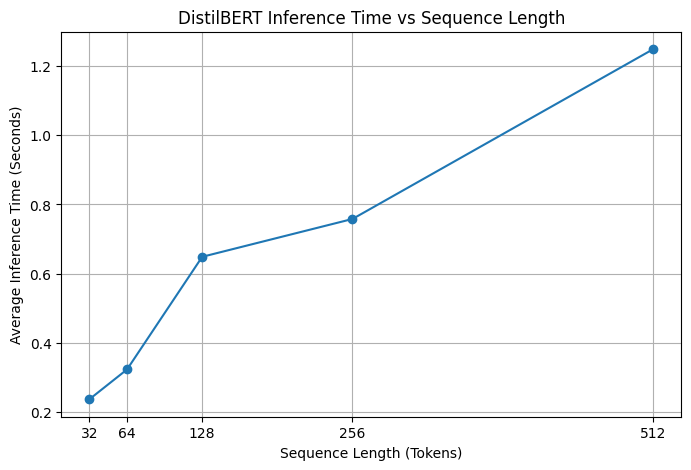

In [69]:
plt.figure(figsize=(8, 5))
plt.plot(lengths, inference_times, marker="o")

plt.title("DistilBERT Inference Time vs Sequence Length")
plt.xlabel("Sequence Length (Tokens)")
plt.ylabel("Average Inference Time (Seconds)")
plt.xticks(lengths)
plt.grid(True)
plt.savefig("inference_time_vs_sequence_length.png")
plt.show()

**Observation:**

The inference time increased as the sequence length increased. At 32 tokens, the average inference time was 0.2376 seconds, while at 512 tokens it was 1.2483 seconds.

This demonstrates that processing longer sequences requires more computation. Self-attention has a theoretical quadratic relationship with sequence length (O(n²)), although the measured timings do not necessarily follow an exact quadratic curve.

The experiment was performed using DistilBERT on CPU, with 10 measured runs after one warm-up run for each sequence length.

### 6.4 Factual Knowledge and Hallucinations in GPT-2

In this experiment, I test GPT-2 using three factual prompts. I generate up to 30 new tokens for each prompt using greedy decoding and manually evaluate whether the answers are correct, partially correct or incorrect.

In [70]:
factual_prompts = [
    "The capital of Australia is",
    "Pride and Prejudice was written by",
    "The telephone was invented by"
]

for prompt in factual_prompts:

    inputs = gpt_tokenizer(prompt, return_tensors="pt")

    with torch.no_grad():
        outputs = gpt_model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False,
            pad_token_id=gpt_tokenizer.eos_token_id
        )

    generated_text = gpt_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("Prompt:", prompt)
    print("GPT-2:", generated_text)
    print("-" * 60)

Prompt: The capital of Australia is
GPT-2: The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest
------------------------------------------------------------
Prompt: Pride and Prejudice was written by
GPT-2: Pride and Prejudice was written by the author of the book, and is available for purchase from Amazon.com.

The book is available for purchase from Amazon.com.

------------------------------------------------------------
Prompt: The telephone was invented by
GPT-2: The telephone was invented by a man named John D. Rockefeller, who was a member of the Rockefeller family. He was a member of the Rockefeller family's board of directors.
------------------------------------------------------------


**Observation:**

GPT-2 was tested using three factual prompts with greedy decoding and a maximum of 30 new tokens.

The model failed to provide correct answers to all three questions. It did not identify Canberra as the capital of Australia, did not name Jane Austen as the author of Pride and Prejudice, and incorrectly attributed the invention of the telephone to John D. Rockefeller.

This experiment demonstrates that GPT-2 can generate fluent but factually incorrect responses. Such outputs are examples of hallucinations. Therefore, generated information should be verified before being trusted.

## Task 6.5 —Build your own text_toolkit()

Understand the function

In [71]:
{
    "sentiment": "POSITIVE",
    "sentiment_score": 0.99,
    "summary": "...",
    "french_translation": "..."
}

{'sentiment': 'POSITIVE',
 'sentiment_score': 0.99,
 'summary': '...',
 'french_translation': '...'}

In [72]:
print("Sentiment model:", sentiment_model.model.name_or_path)
print("Sentiment tokenizer:", sentiment_model.tokenizer.name_or_path)

print("T5 model:", model.name_or_path)
print("T5 tokenizer:", tokenizer.name_or_path)

Sentiment model: distilbert-base-uncased-finetuned-sst-2-english
Sentiment tokenizer: distilbert-base-uncased-finetuned-sst-2-english
T5 model: t5-small
T5 tokenizer: t5-small


The text_toolkit() function combines three NLP tasks: sentiment analysis, text summarization and English-to-French translation. It accepts a text passage and returns the results in a Python dictionary.

Task 6.5 — Handle empty and very long inputs

In [73]:
def text_toolkit(text):

    # 1. Sentiment Analysis
    sentiment_result = sentiment_model(
        text,
        truncation=True,
        max_length=512
    )[0]

    # 2. Text Summarization
    summary_input = "summarize: " + text

    summary_tokens = tokenizer(
        summary_input,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        summary_output = model.generate(
            **summary_tokens,
            max_length=60
        )

    summary = tokenizer.decode(
        summary_output[0],
        skip_special_tokens=True
    )

    # 3. French Translation
    translation_input = "translate English to French: " + summary

    translation_tokens = tokenizer(
        translation_input,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        translation_output = model.generate(
            **translation_tokens,
            max_length=60
        )

    french_translation = tokenizer.decode(
        translation_output[0],
        skip_special_tokens=True
    )

    # Return all results
    return {
        "sentiment": sentiment_result["label"],
        "sentiment_score": round(sentiment_result["score"], 4),
        "summary": summary,
        "french_translation": french_translation
    }

Test the function

In [74]:
sample_text = """
Artificial intelligence is transforming healthcare.
Doctors use AI to analyze medical images, detect diseases,
and support clinical decisions. AI tools can also help
hospitals manage patient records and improve efficiency.
"""

result = text_toolkit(sample_text)

for key, value in result.items():
    print(f"{key}: {value}")

sentiment: POSITIVE
sentiment_score: 0.9978
summary: AI tools can help hospitals manage patient records and improve efficiency.
french_translation: Les outils d'AI peuvent aider les hôpitaux à gérer les dossiers des patients et à améliorer leur efficacité.


Test on three different passages

In [75]:
test_passages = {
    "Movie Review": """
    The movie was absolutely fantastic. The acting was brilliant,
    the story was engaging, and the background music made every
    scene enjoyable. I would definitely recommend it.
    """,

    "News Paragraph": """
    Scientists are developing new artificial intelligence systems
    to improve weather forecasting. These systems analyze large
    amounts of climate data and help predict extreme weather events.
    """,

    "Personal Passage": """
    I am learning artificial intelligence and machine learning.
    I enjoy building practical projects because they help me
    understand how technology works in real-world situations.
    """
}

import pandas as pd

results = []

for name, passage in test_passages.items():

    output = text_toolkit(passage)

    results.append({
        "Passage": name,
        "Sentiment": output["sentiment"],
        "Score": output["sentiment_score"],
        "Summary": output["summary"],
        "French Translation": output["french_translation"]
    })

results_df = pd.DataFrame(results)

results_df

,Passage,Sentiment,Score,Summary,French Translation
0,Movie Review,POSITIVE,0.9999,"the acting was brilliant, the story was engagi...","l'acteur a été brillant, l'histoire a été inté..."
1,News Paragraph,POSITIVE,0.9808,artificial intelligence systems analyze large ...,Les systèmes d'intelligence artificielle analy...
2,Personal Passage,POSITIVE,0.9996,I am learning artificial intelligence and mach...,Je m'aperçois l'intelligence artificielle et l...


Handle empty and very long inputs

In [78]:
def text_toolkit(text):

    # Handle empty input
    if not isinstance(text, str) or not text.strip():
        return {
            "message": "Please provide a non-empty text passage."
        }

    # Check input length
    token_count = (
    len(tokenizer.tokenize(text))
    + tokenizer.num_special_tokens_to_add(pair=False)
)

    message = "Input processed successfully."

    if token_count > 512:
        message = "Input was longer than 512 tokens and was truncated."

    # 1. Sentiment Analysis
    sentiment_result = sentiment_model(
        text,
        truncation=True,
        max_length=512
    )[0]

    # 2. Summarization
    summary_tokens = tokenizer(
        "summarize: " + text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        summary_output = model.generate(
            **summary_tokens,
            max_length=60
        )

    summary = tokenizer.decode(
        summary_output[0],
        skip_special_tokens=True
    )

    # 3. French Translation
    translation_tokens = tokenizer(
        "translate English to French: " + summary,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        translation_output = model.generate(
            **translation_tokens,
            max_length=60
        )

    french_translation = tokenizer.decode(
        translation_output[0],
        skip_special_tokens=True
    )

    return {
        "sentiment": sentiment_result["label"],
        "sentiment_score": round(sentiment_result["score"], 4),
        "summary": summary,
        "french_translation": french_translation,
        "message": message
    }

Test the safeguards

In [79]:
# Test 1: Empty input
print(text_toolkit(""))

# Test 2: Very long input
long_text = "Artificial intelligence is transforming healthcare. " * 150

long_result = text_toolkit(long_text)

print(long_result)

{'message': 'Please provide a non-empty text passage.'}
{'sentiment': 'POSITIVE', 'sentiment_score': 0.9044, 'summary': 'artificial intelligence is transforming healthcare. Artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is transforming healthcare. artificial intelligence is', 'french_translation': 'L’intelligence artificielle transforme les soins de santé. L’intelligence artificielle transforme les soins de santé. L’intelligence artificielle transforme les soins de santé. L’intelligence artificielle transforme les soins de santé. L’intelligence', 'message': 'Input was longer than 512 tokens and was truncated.'}


## 6.6 Reflection: What I Learned About Transformers

Set random seeds

In [80]:
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Random seeds set successfully.")

Random seeds set successfully.


Check installed library versions

In [81]:
import transformers
import torch
import datasets
import numpy
import pandas
import matplotlib

print("transformers:", transformers.__version__)
print("torch:", torch.__version__)
print("datasets:", datasets.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("matplotlib:", matplotlib.__version__)

transformers: 5.21.0
torch: 2.14.1+cpu
datasets: 5.1.0
numpy: 2.4.6
pandas: 3.0.0
matplotlib: 3.10.8


In [82]:
requirements = """
transformers==5.21.0
torch==2.14.1+cpu
datasets==5.1.0
numpy==2.4.6
pandas==3.0.0
matplotlib==3.10.8
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip() + "\n")

print("requirements.txt updated successfully!")

requirements.txt updated successfully!


In [83]:
with open("requirements.txt", "r") as file:
    print(file.read())

transformers==5.21.0
torch==2.14.1+cpu
datasets==5.1.0
numpy==2.4.6
pandas==3.0.0
matplotlib==3.10.8

